---
# COSC2673 Machine Learning
## Assessment 3: **Image Classification**
### Author: Rahul Garg (s4008144)
---

## Section 1: Task Definition

### Background

Colorectal cancer is one of the most common and deadly cancers worldwide. Detecting it early can dramatically improve a patient's chances of survival. Traditionally, a trained pathologist manually examines tissue samples under a microscope to identify cancerous cells. This process is slow, expensive, and can vary between different experts.

This project applies machine learning to **automate** the analysis of **histopathology images**, which are microscopic photographs of individual colon tissue cells. By training models to recognise patterns in these images, we can build tools that assist pathologists in making faster and more consistent diagnoses.

---

### Dataset

The dataset used is the **CRCHistoPhenotypes** (Colorectal Cancer Histology Phenotypes) dataset. Each image is a **27×27 pixel RGB** patch centred on a single colon cell from a patient tissue sample.

- **Image size:** 27×27 pixels, RGB colour
- **Total patients:** 99
- **mainData:** 60 patients, labelled with cancer status and cell type
- **extraData:** 39 patients, labelled with cancer status only

---

### Task 1: Cancer Detection (Binary Classification)

> **"Is this cell cancerous?"**

- `0` = **Non-Cancerous** — the cell appears normal
- `1` = **Cancerous** — the cell shows signs of cancer

**Data used:** All 99 patients (mainData + extraData combined).

**Motivation:** A reliable detection model could act as a first-pass screening tool, automatically flagging suspicious cells for a pathologist to review, reducing workload and the risk of missed diagnoses.

**Target:** Macro-averaged F1-score ≥ **0.90** on unseen patients

---

### Task 2: Cell-Type Classification (Multi-Class Classification)

> **"What type of cell is this?"**

- `0` = **Fibroblast** — connective tissue cells that form the structural framework of the colon
- `1` = **Inflammatory** — immune system cells that respond to infection or injury
- `2` = **Epithelial** — lining cells of the colon wall, most associated with colorectal cancer
- `3` = **Others** — cells that do not fall into the above three categories

**Data used:** 60 patients from mainData only.

**Motivation:** Identifying the mix of cell types surrounding a tumour helps doctors understand how aggressive a cancer is and which treatments are most likely to work.

**Target:** Macro-averaged F1-score ≥ **0.60** on unseen patients

---

### Evaluation Framework

Models must generalise to **entirely new patients** not seen during training, reflecting real clinical deployment conditions.

**Splitting strategy (patient-level):**
- All 99 patients are split so that every image from a patient goes entirely into one set only
- **Test set (20% of patients):** held out entirely, never used during training or validation
- **Training set (64% of patients):** used to fit all models
- **Validation set (16% of patients):** used to tune hyperparameters and monitor overfitting

**Metrics:**
- **Accuracy** — percentage of images classified correctly
- **Macro-averaged F1-score** — F1 computed per class then averaged equally across all classes, regardless of class size. This is the primary metric as it penalises models that ignore smaller or harder classes, which is critical in a medical context.

All random operations use a fixed seed of `42` for reproducibility.

## Section 2: Imports and Setup

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Paths
DATA_DIR  = './dataset'
IMAGE_DIR = os.path.join(DATA_DIR, 'images')
MAIN_CSV  = os.path.join(DATA_DIR, 'data_labels_mainData.csv')
EXTRA_CSV = os.path.join(DATA_DIR, 'data_labels_extraData.csv')

device = torch.device('mps' if torch.backends.mps.is_available() 
                       else 'cuda' if torch.cuda.is_available() 
                       else 'cpu')
print(f"Using device: {device}")

Using device: mps


## Section 3: Dataset Description and EDA

### 3.1 Load Data

In [2]:
main_df  = pd.read_csv(MAIN_CSV)
extra_df = pd.read_csv(EXTRA_CSV)

# Combined dataset for Task 1 (isCancerous) using all 99 patients
task1_df = pd.concat([
    main_df[['InstanceID', 'patientID', 'ImageName', 'isCancerous']],
    extra_df[['InstanceID', 'patientID', 'ImageName', 'isCancerous']]
], ignore_index=True)

# Task 2 uses mainData only (only source of cell-type labels)
task2_df = main_df.copy()

print("=== mainData ===")
print(f"  Images:   {len(main_df)}")
print(f"  Patients: {main_df['patientID'].nunique()}")
print(f"  Columns:  {list(main_df.columns)}")
print()
print("=== extraData ===")
print(f"  Images:   {len(extra_df)}")
print(f"  Patients: {extra_df['patientID'].nunique()}")
print(f"  Columns:  {list(extra_df.columns)}")
print()
print("=== Task 1 Combined ===")
print(f"  Total images:   {len(task1_df)}")
print(f"  Total patients: {task1_df['patientID'].nunique()}")
print()
print("Task 1 — isCancerous class counts:")
print(task1_df['isCancerous'].value_counts().rename({0: 'Non-Cancerous', 1: 'Cancerous'}).to_string())
print()
print("Task 2 — Cell-type class counts:")
print(task2_df['cellTypeName'].value_counts().to_string())

=== mainData ===
  Images:   9896
  Patients: 60
  Columns:  ['InstanceID', 'patientID', 'ImageName', 'cellTypeName', 'cellType', 'isCancerous']

=== extraData ===
  Images:   10384
  Patients: 38
  Columns:  ['InstanceID', 'patientID', 'ImageName', 'isCancerous']

=== Task 1 Combined ===
  Total images:   20280
  Total patients: 98

Task 1 — isCancerous class counts:
isCancerous
Non-Cancerous    13211
Cancerous         7069

Task 2 — Cell-type class counts:
cellTypeName
epithelial      4079
inflammatory    2543
fibroblast      1888
others          1386


> **Note:** The dataset specification states 99 patients, however the combined CSV files contain only 98 unique patient IDs. All 98 available patients are used throughout this notebook.

### 3.2 Class Distribution

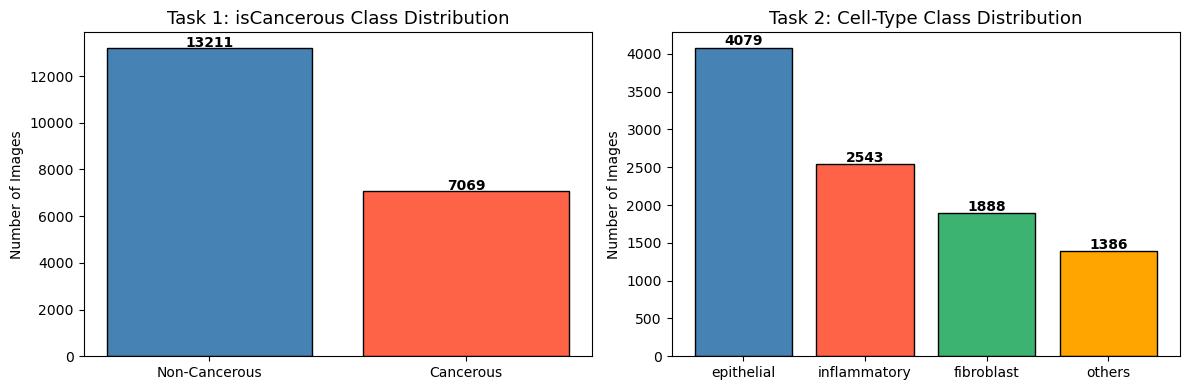

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Task 1 bar chart
counts1 = task1_df['isCancerous'].value_counts().sort_index()
axes[0].bar(['Non-Cancerous', 'Cancerous'], counts1.values,
            color=['steelblue', 'tomato'], edgecolor='black')
axes[0].set_title('Task 1: isCancerous Class Distribution', fontsize=13)
axes[0].set_ylabel('Number of Images')
for i, v in enumerate(counts1.values):
    axes[0].text(i, v + 30, str(v), ha='center', fontweight='bold')

# Task 2 bar chart
counts2 = task2_df['cellTypeName'].value_counts()
axes[1].bar(counts2.index, counts2.values,
            color=['steelblue', 'tomato', 'mediumseagreen', 'orange'], edgecolor='black')
axes[1].set_title('Task 2: Cell-Type Class Distribution', fontsize=13)
axes[1].set_ylabel('Number of Images')
for i, v in enumerate(counts2.values):
    axes[1].text(i, v + 30, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 3.3 Sample Images

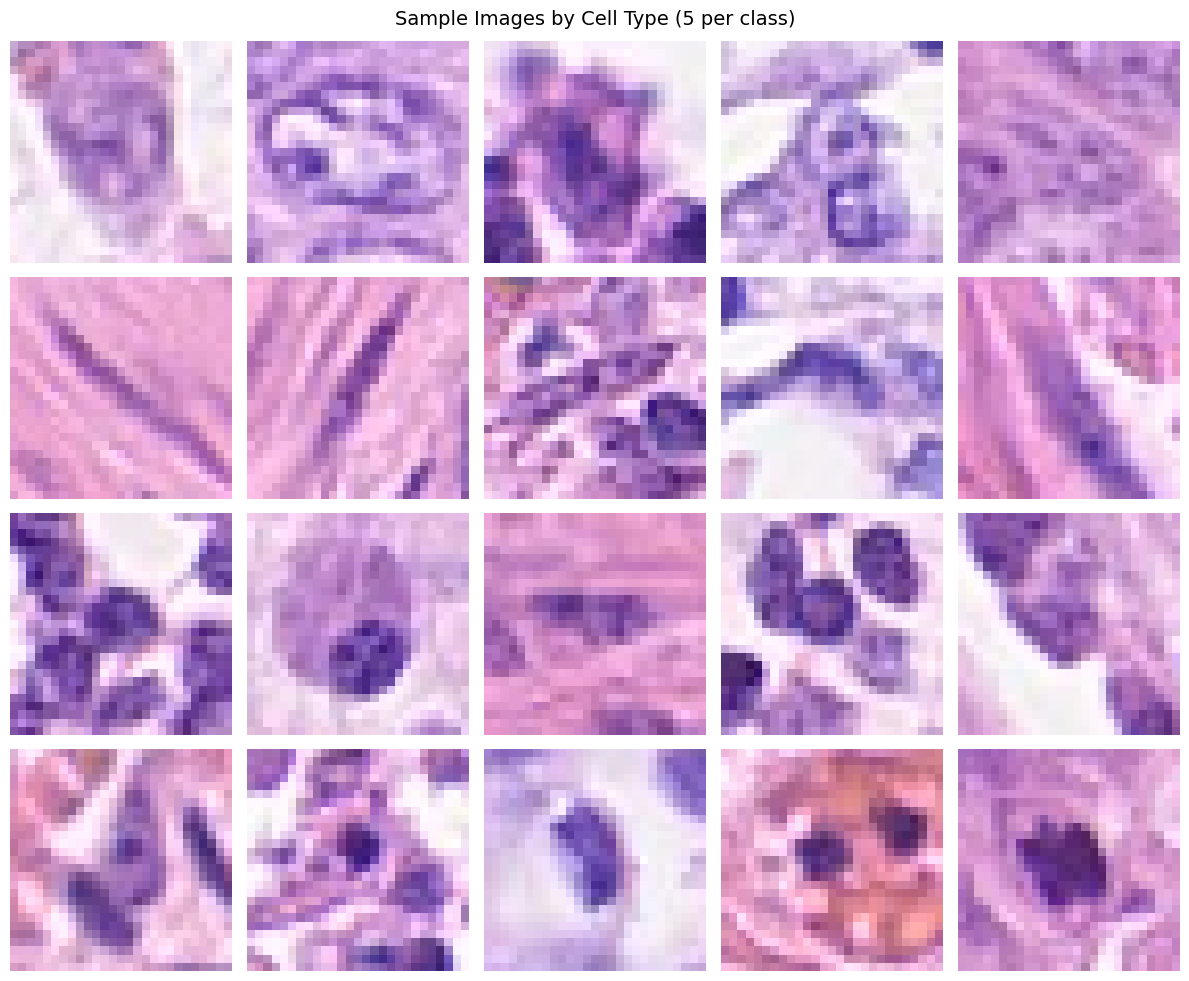

In [4]:
cell_types = sorted(task2_df['cellTypeName'].unique())
fig, axes = plt.subplots(len(cell_types), 5, figsize=(12, 10))

for row_idx, ctype in enumerate(cell_types):
    subset = task2_df[task2_df['cellTypeName'] == ctype].sample(5, random_state=SEED)
    for col_idx, (_, row) in enumerate(subset.iterrows()):
        img = Image.open(os.path.join(IMAGE_DIR, row['ImageName'])).convert('RGB')
        axes[row_idx, col_idx].imshow(img)
        axes[row_idx, col_idx].axis('off')
        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(ctype, fontsize=11,
                                               rotation=0, labelpad=60, va='center')

fig.suptitle('Sample Images by Cell Type (5 per class)', fontsize=14)
plt.tight_layout()
plt.show()

### 3.4 Unsupervised EDA: PCA, K-Means and t-SNE

Unlike tabular data where EDA focuses on missing values and feature distributions, image EDA focuses on understanding pixel-level structure. Here we flatten each 27×27×3 image into a 2187-dimensional vector and apply unsupervised techniques to visualise whether natural groupings exist in the data before any model is trained.

In [5]:
# Load all images and flatten
def load_images_flat(df, image_dir):
    pixels = []
    for _, row in df.iterrows():
        img = Image.open(os.path.join(image_dir, row['ImageName'])).convert('RGB')
        pixels.append(np.array(img).flatten().astype(np.float32) / 255.0)
    return np.stack(pixels)

print("Loading Task 2 images for EDA...")
X_flat = load_images_flat(task2_df, IMAGE_DIR)
y_type = task2_df['cellType'].values
y_canc = task2_df['isCancerous'].values
type_names = {0: 'fibroblast', 1: 'inflammatory', 2: 'epithelial', 3: 'others'}

print(f"Loaded {X_flat.shape[0]} images, each flattened to {X_flat.shape[1]} features")

Loading Task 2 images for EDA...
Loaded 9896 images, each flattened to 2187 features


#### PCA: Variance Explained

We first standardise the pixel vectors and apply PCA to understand how much variance is captured by the leading components.

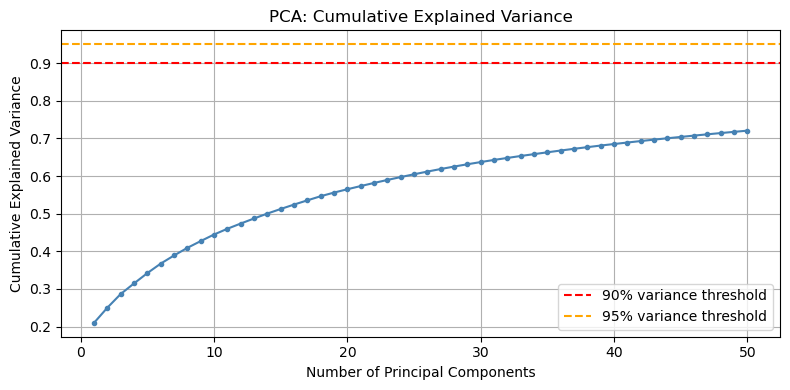

Components needed to explain 90% of variance: 1
Components needed to explain 95% of variance: 1


In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_flat)

pca_full = PCA(n_components=50, random_state=SEED)
pca_full.fit(X_scaled)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 51), cumvar, marker='o', markersize=3, color='steelblue')
plt.axhline(0.90, color='red', linestyle='--', label='90% variance threshold')
plt.axhline(0.95, color='orange', linestyle='--', label='95% variance threshold')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA: Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

n_90 = np.argmax(cumvar >= 0.90) + 1
n_95 = np.argmax(cumvar >= 0.95) + 1
print(f"Components needed to explain 90% of variance: {n_90}")
print(f"Components needed to explain 95% of variance: {n_95}")

#### PCA 2D Visualisation

We reduce to 2 principal components to visualise the data. If classes form visible clusters, it suggests that raw pixel features carry discriminative information.

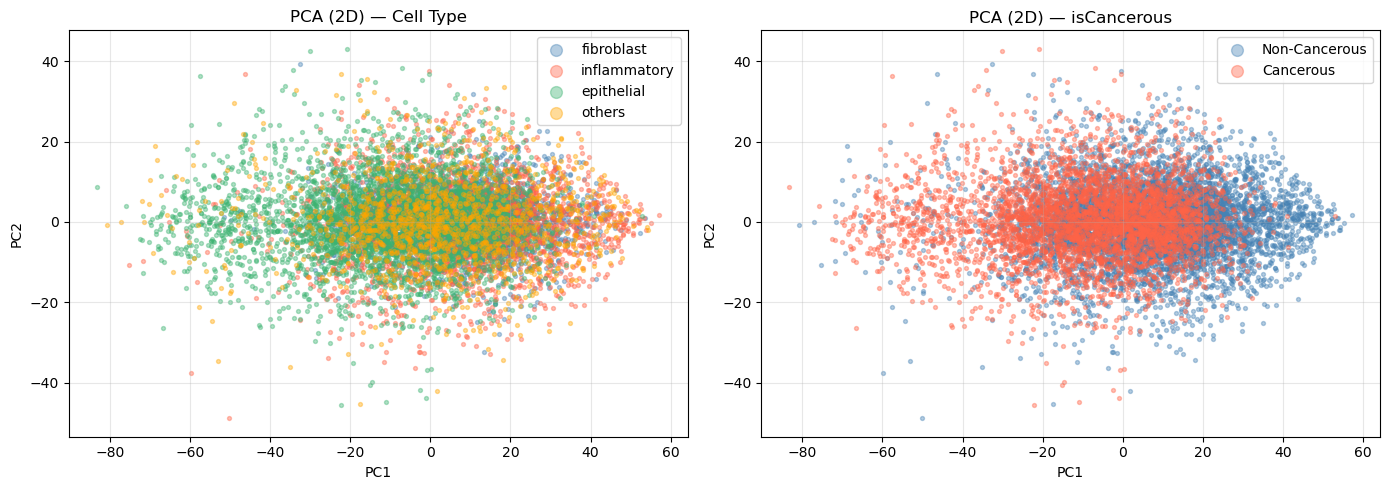

In [7]:
pca_2d = PCA(n_components=2, random_state=SEED)
X_pca2d = pca_2d.fit_transform(X_scaled)

colors = ['steelblue', 'tomato', 'mediumseagreen', 'orange']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for cls in range(4):
    mask = y_type == cls
    axes[0].scatter(X_pca2d[mask, 0], X_pca2d[mask, 1],
                    c=colors[cls], label=type_names[cls], alpha=0.4, s=8)
axes[0].set_title('PCA (2D) — Cell Type')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(markerscale=3)
axes[0].grid(True, alpha=0.3)

for cls, label, color in zip([0, 1], ['Non-Cancerous', 'Cancerous'], ['steelblue', 'tomato']):
    mask = y_canc == cls
    axes[1].scatter(X_pca2d[mask, 0], X_pca2d[mask, 1],
                    c=color, label=label, alpha=0.4, s=8)
axes[1].set_title('PCA (2D) — isCancerous')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(markerscale=3)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### K-Means Clustering

We apply K-Means with k=4 (matching the number of cell types) on the top 50 PCA components to see if unsupervised clusters align with the true cell-type labels.

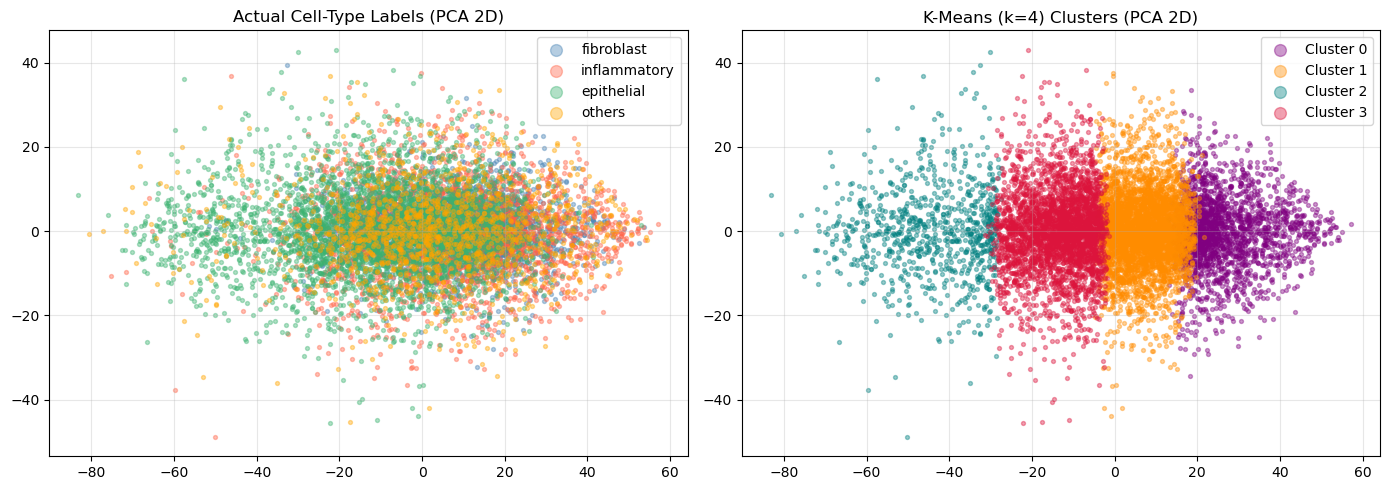

In [8]:
pca_50 = PCA(n_components=50, random_state=SEED)
X_pca50 = pca_50.fit_transform(X_scaled)

kmeans = KMeans(n_clusters=4, random_state=SEED, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca50)

cluster_colors = ['purple', 'darkorange', 'teal', 'crimson']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for cls in range(4):
    mask = y_type == cls
    axes[0].scatter(X_pca2d[mask, 0], X_pca2d[mask, 1],
                    c=colors[cls], label=type_names[cls], alpha=0.4, s=8)
axes[0].set_title('Actual Cell-Type Labels (PCA 2D)')
axes[0].legend(markerscale=3)
axes[0].grid(True, alpha=0.3)

for cls in range(4):
    mask = cluster_labels == cls
    axes[1].scatter(X_pca2d[mask, 0], X_pca2d[mask, 1],
                    c=cluster_colors[cls], label=f'Cluster {cls}', alpha=0.4, s=8)
axes[1].set_title('K-Means (k=4) Clusters (PCA 2D)')
axes[1].legend(markerscale=3)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### t-SNE Visualisation

t-SNE is a non-linear dimensionality reduction technique that better preserves local structure compared to PCA. We apply it on the PCA-50 reduced features for computational efficiency.

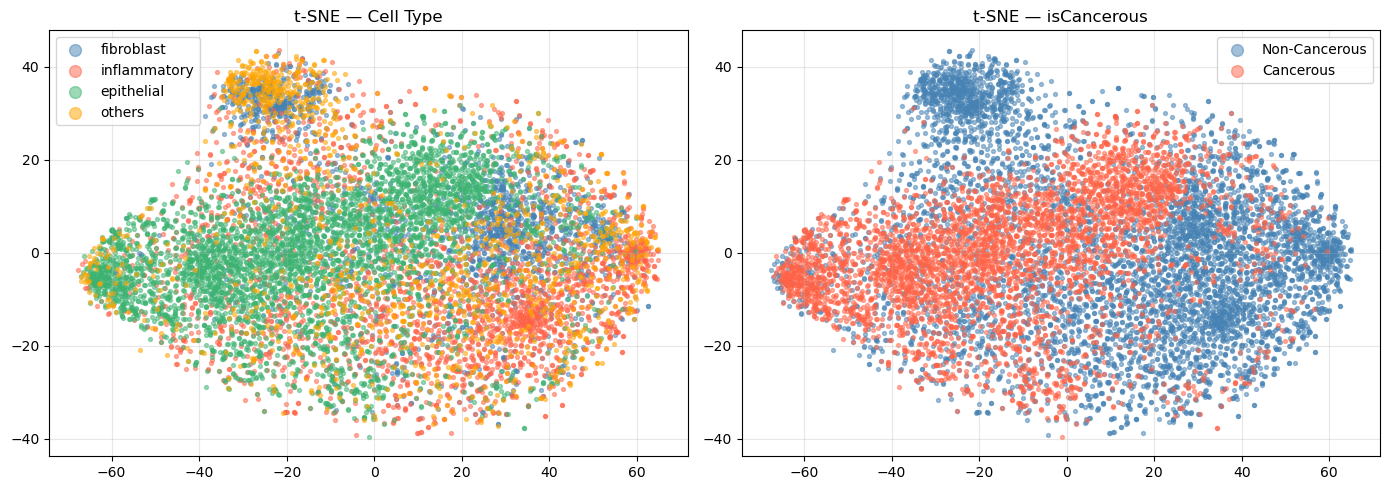

In [9]:
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_pca50)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for cls in range(4):
    mask = y_type == cls
    axes[0].scatter(X_tsne[mask, 0], X_tsne[mask, 1],
                    c=colors[cls], label=type_names[cls], alpha=0.5, s=8)
axes[0].set_title('t-SNE — Cell Type')
axes[0].legend(markerscale=3)
axes[0].grid(True, alpha=0.3)

for cls, label, color in zip([0, 1], ['Non-Cancerous', 'Cancerous'], ['steelblue', 'tomato']):
    mask = y_canc == cls
    axes[1].scatter(X_tsne[mask, 0], X_tsne[mask, 1],
                    c=color, label=label, alpha=0.5, s=8)
axes[1].set_title('t-SNE — isCancerous')
axes[1].legend(markerscale=3)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.5 EDA Summary

**Dataset characteristics:**
- All images are uniform 27×27 RGB patches with no missing values or corrupt files, so no pixel-level cleaning is required
- Class imbalance exists in both tasks and will be addressed using class weights during model training

**PCA findings:**
- The first two principal components capture very little of the total variance, confirming that the pixel feature space is highly complex and high-dimensional
- The 2D PCA plots show heavy overlap between all classes, meaning raw pixel features with a linear projection are not sufficient to separate cell types or cancer status
- There is a slight separation along PC1 for the isCancerous task, which is encouraging but not enough on its own

**K-Means findings:**
- K-Means clusters partition the data along the first principal component, reflecting differences in overall pixel brightness and colour intensity rather than meaningful biological structure
- The K-Means clusters do not align with the actual cell-type labels, confirming that unsupervised clustering on raw pixel features cannot recover the true classes
- This supports the use of supervised learning models that can learn task-specific discriminative features

**t-SNE findings:**
- t-SNE reveals a tight and well-separated cluster of fibroblast cells, suggesting this class has visually distinctive features that supervised models should be able to learn reliably
- Inflammatory and Others classes overlap significantly in the t-SNE embedding, indicating these will be the hardest classes to distinguish
- A small distinct cluster of non-cancerous cells is visible in the isCancerous t-SNE plot, which is a promising sign for Task 1 performance
- The richer structure revealed by t-SNE compared to PCA confirms that the data contains non-linear patterns, motivating the use of CNNs over simple linear classifiers

## Section 4: Data Preprocessing

Unlike tabular data where preprocessing involves encoding categoricals and imputing missing values, image preprocessing focuses on ensuring consistent colour channels, normalising pixel values, and preparing data loaders for efficient batch training.

The key preprocessing steps are:
- **Patient-level splitting** to ensure no patient appears in both train and test sets
- **Pixel normalisation** using mean and standard deviation computed from the training set only, preventing data leakage and ensuring dataset-specific scaling
- **Class weight computation** to handle class imbalance identified in EDA
- **Data augmentation** applied to training images only to improve generalisation (used in CNN models)

### 4.1 Patient-Level Train/Validation/Test Split

In [10]:
from sklearn.model_selection import train_test_split

def patient_split(df, test_size=0.2, val_size=0.2, seed=SEED):
    patients = df['patientID'].unique()
    
    # Split off test patients first
    train_val_patients, test_patients = train_test_split(
        patients, test_size=test_size, random_state=seed
    )
    # Split remaining into train and validation
    train_patients, val_patients = train_test_split(
        train_val_patients, test_size=val_size, random_state=seed
    )
    
    train_df = df[df['patientID'].isin(train_patients)].reset_index(drop=True)
    val_df   = df[df['patientID'].isin(val_patients)].reset_index(drop=True)
    test_df  = df[df['patientID'].isin(test_patients)].reset_index(drop=True)
    
    return train_df, val_df, test_df

# Task 1 split (98 patients)
t1_train, t1_val, t1_test = patient_split(task1_df)

# Task 2 split (60 patients)
t2_train, t2_val, t2_test = patient_split(task2_df)

print("=== Task 1: isCancerous ===")
print(f"  Train:      {len(t1_train)} images | {t1_train['patientID'].nunique()} patients")
print(f"  Validation: {len(t1_val)} images | {t1_val['patientID'].nunique()} patients")
print(f"  Test:       {len(t1_test)} images | {t1_test['patientID'].nunique()} patients")
print()
print("=== Task 2: Cell-Type ===")
print(f"  Train:      {len(t2_train)} images | {t2_train['patientID'].nunique()} patients")
print(f"  Validation: {len(t2_val)} images | {t2_val['patientID'].nunique()} patients")
print(f"  Test:       {len(t2_test)} images | {t2_test['patientID'].nunique()} patients")

# Verify no patient overlap
assert len(set(t1_train['patientID']) & set(t1_test['patientID'])) == 0
assert len(set(t1_val['patientID'])   & set(t1_test['patientID'])) == 0
assert len(set(t2_train['patientID']) & set(t2_test['patientID'])) == 0
assert len(set(t2_val['patientID'])   & set(t2_test['patientID'])) == 0
print("\nPatient overlap check passed — no patients shared between splits.")

=== Task 1: isCancerous ===
  Train:      12319 images | 62 patients
  Validation: 4005 images | 16 patients
  Test:       3956 images | 20 patients

=== Task 2: Cell-Type ===
  Train:      6215 images | 38 patients
  Validation: 1842 images | 10 patients
  Test:       1839 images | 12 patients

Patient overlap check passed — no patients shared between splits.


### 4.2 Image Integrity Check

We verify that every image referenced in the CSV files exists on disk and can be opened correctly. This ensures no corrupt or missing files cause silent failures during training.

In [11]:
def check_images(df, image_dir):
    missing, corrupt = [], []
    for _, row in df.iterrows():
        path = os.path.join(image_dir, row['ImageName'])
        if not os.path.exists(path):
            missing.append(row['ImageName'])
        else:
            try:
                Image.open(path).verify()
            except Exception:
                corrupt.append(row['ImageName'])
    return missing, corrupt

print("Checking all images in task1_df...")
missing, corrupt = check_images(task1_df, IMAGE_DIR)
print(f"  Missing: {len(missing)} | Corrupt: {len(corrupt)}")

print("Checking all images in task2_df...")
missing2, corrupt2 = check_images(task2_df, IMAGE_DIR)
print(f"  Missing: {len(missing2)} | Corrupt: {len(corrupt2)}")

if not missing and not corrupt and not missing2 and not corrupt2:
    print("\nAll images verified successfully — no missing or corrupt files found.")

Checking all images in task1_df...
  Missing: 0 | Corrupt: 0
Checking all images in task2_df...
  Missing: 0 | Corrupt: 0

All images verified successfully — no missing or corrupt files found.


### 4.3 Pixel Value Distribution

We compute normalisation statistics (mean and std) from the training set only to avoid data leakage, and visualise the pixel value distribution before and after normalisation. Histopathology images tend to be bright and lightly stained, which is reflected in the right-skewed raw distribution. Normalisation centres the pixel values and reduces variance, which stabilises gradient updates during CNN training.

Dataset mean: (np.float64(0.757), np.float64(0.599), np.float64(0.822))
Dataset std:  (np.float64(0.151), np.float64(0.166), np.float64(0.104))


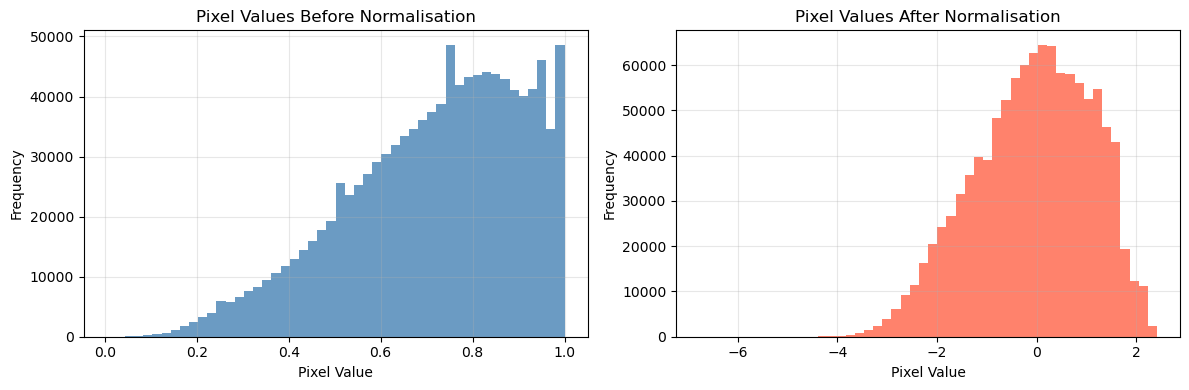

Before — Min: 0.004, Max: 1.000, Mean: 0.717
After  — Min: -6.773, Max: 2.416, Mean: -0.077


In [12]:
# Compute mean and std from training images only
mean_sum = np.zeros(3)
std_sum  = np.zeros(3)
count    = 0

for _, row in t1_train.iterrows():
    img = np.array(Image.open(os.path.join(IMAGE_DIR, row['ImageName'])).convert('RGB')).astype(np.float32) / 255.0
    mean_sum += img.mean(axis=(0, 1))
    std_sum  += img.std(axis=(0, 1))
    count    += 1

IMG_MEAN = tuple((mean_sum / count).round(3))
IMG_STD  = tuple((std_sum  / count).round(3))

print(f"Dataset mean: {IMG_MEAN}")
print(f"Dataset std:  {IMG_STD}")

# Visualise pixel distribution before and after normalisation
sample_check = task2_df.sample(500, random_state=SEED)
raw_pixels, norm_pixels = [], []

to_tensor = transforms.ToTensor()
normalise = transforms.Normalize(IMG_MEAN, IMG_STD)

for _, row in sample_check.iterrows():
    img = Image.open(os.path.join(IMAGE_DIR, row['ImageName'])).convert('RGB')
    t   = to_tensor(img)
    raw_pixels.append(t.numpy().flatten())
    norm_pixels.append(normalise(t).numpy().flatten())

raw_pixels  = np.concatenate(raw_pixels)
norm_pixels = np.concatenate(norm_pixels)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(raw_pixels,  bins=50, color='steelblue', edgecolor='none', alpha=0.8)
axes[0].set_title('Pixel Values Before Normalisation')
axes[0].set_xlabel('Pixel Value')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, alpha=0.3)

axes[1].hist(norm_pixels, bins=50, color='tomato', edgecolor='none', alpha=0.8)
axes[1].set_title('Pixel Values After Normalisation')
axes[1].set_xlabel('Pixel Value')
axes[1].set_ylabel('Frequency')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Before — Min: {raw_pixels.min():.3f}, Max: {raw_pixels.max():.3f}, Mean: {raw_pixels.mean():.3f}")
print(f"After  — Min: {norm_pixels.min():.3f}, Max: {norm_pixels.max():.3f}, Mean: {norm_pixels.mean():.3f}")

### 4.4 PyTorch Dataset and DataLoaders

We define a reusable `CRCDataset` class for loading images from disk. Pixel values are normalised using the mean and std computed from the training set above, ensuring normalisation is dataset-specific and avoids data leakage. Data augmentation (random horizontal flip, vertical flip, and rotation) is applied to training data only to improve generalisation.

In [13]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMG_MEAN, IMG_STD)
])

val_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMG_MEAN, IMG_STD)
])

class CRCDataset(Dataset):
    def __init__(self, df, image_dir, label_col, transform=None):
        self.df        = df.reset_index(drop=True)
        self.image_dir = image_dir
        self.label_col = label_col
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(os.path.join(self.image_dir, row['ImageName'])).convert('RGB')
        label = int(row[self.label_col])
        if self.transform:
            image = self.transform(image)
        return image, label

BATCH_SIZE = 32

# Task 1 loaders
t1_train_loader = DataLoader(CRCDataset(t1_train, IMAGE_DIR, 'isCancerous', train_transform),
                              batch_size=BATCH_SIZE, shuffle=True)
t1_val_loader   = DataLoader(CRCDataset(t1_val,   IMAGE_DIR, 'isCancerous', val_test_transform),
                              batch_size=BATCH_SIZE, shuffle=False)
t1_test_loader  = DataLoader(CRCDataset(t1_test,  IMAGE_DIR, 'isCancerous', val_test_transform),
                              batch_size=BATCH_SIZE, shuffle=False)

# Task 2 loaders
t2_train_loader = DataLoader(CRCDataset(t2_train, IMAGE_DIR, 'cellType', train_transform),
                              batch_size=BATCH_SIZE, shuffle=True)
t2_val_loader   = DataLoader(CRCDataset(t2_val,   IMAGE_DIR, 'cellType', val_test_transform),
                              batch_size=BATCH_SIZE, shuffle=False)
t2_test_loader  = DataLoader(CRCDataset(t2_test,  IMAGE_DIR, 'cellType', val_test_transform),
                              batch_size=BATCH_SIZE, shuffle=False)

### 4.5 Class Weights

Class imbalance was identified in EDA for both tasks. We compute class weights inversely proportional to class frequency and pass them to the loss function during training, ensuring the model does not bias towards the majority class.

In [14]:
from sklearn.utils.class_weight import compute_class_weight

def get_class_weights(df, label_col, device):
    labels  = df[label_col].values
    classes = np.unique(labels)
    weights = compute_class_weight(class_weight='balanced', classes=classes, y=labels)
    return torch.FloatTensor(weights).to(device)

# Task 1 class weights (binary)
t1_class_weights = get_class_weights(t1_train, 'isCancerous', device)
print("Task 1 class weights (Non-Cancerous, Cancerous):", t1_class_weights)

# Task 2 class weights (4-class)
t2_class_weights = get_class_weights(t2_train, 'cellType', device)
print("Task 2 class weights (fibroblast, inflammatory, epithelial, others):", t2_class_weights)

Task 1 class weights (Non-Cancerous, Cancerous): tensor([0.7705, 1.4242], device='mps:0')
Task 2 class weights (fibroblast, inflammatory, epithelial, others): tensor([1.1762, 0.8296, 0.6830, 2.0828], device='mps:0')


### 4.6 Flattened Features for Traditional ML Models

SVM and Random Forest operate on flat feature vectors rather than 3D image tensors. We preprocess a flattened version of the pixel data, normalised to [0, 1], for use with sklearn models.

In [15]:
def df_to_flat_arrays(df, image_dir, label_col):
    X, y = [], []
    for _, row in df.iterrows():
        img = Image.open(os.path.join(image_dir, row['ImageName'])).convert('RGB')
        X.append(np.array(img).flatten().astype(np.float32) / 255.0)
        y.append(int(row[label_col]))
    return np.stack(X), np.array(y)

print("Preparing flat arrays for Task 1...")
X_t1_train, y_t1_train = df_to_flat_arrays(t1_train, IMAGE_DIR, 'isCancerous')
X_t1_val,   y_t1_val   = df_to_flat_arrays(t1_val,   IMAGE_DIR, 'isCancerous')
X_t1_test,  y_t1_test  = df_to_flat_arrays(t1_test,  IMAGE_DIR, 'isCancerous')

print("Preparing flat arrays for Task 2...")
X_t2_train, y_t2_train = df_to_flat_arrays(t2_train, IMAGE_DIR, 'cellType')
X_t2_val,   y_t2_val   = df_to_flat_arrays(t2_val,   IMAGE_DIR, 'cellType')
X_t2_test,  y_t2_test  = df_to_flat_arrays(t2_test,  IMAGE_DIR, 'cellType')

print(f"\nTask 1 flat shapes — Train: {X_t1_train.shape}, Val: {X_t1_val.shape}, Test: {X_t1_test.shape}")
print(f"Task 2 flat shapes — Train: {X_t2_train.shape}, Val: {X_t2_val.shape}, Test: {X_t2_test.shape}")

Preparing flat arrays for Task 1...
Preparing flat arrays for Task 2...

Task 1 flat shapes — Train: (12319, 2187), Val: (4005, 2187), Test: (3956, 2187)
Task 2 flat shapes — Train: (6215, 2187), Val: (1842, 2187), Test: (1839, 2187)


### 4.7 PCA Dimensionality Reduction for Traditional ML Models

SVM and Random Forest operating on raw 2187-dimensional pixel vectors (27×27×3) would be computationally expensive and prone to the curse of dimensionality. We apply PCA to reduce the feature space to the number of components that explain 95% of the variance, as identified in the EDA. This significantly reduces training time while retaining the most informative structure in the data.

In [16]:
from sklearn.decomposition import PCA

# Fit PCA on Task 1 training data and apply to all splits
pca_t1 = PCA(n_components=0.95, random_state=SEED)
X_t1_train_pca = pca_t1.fit_transform(X_t1_train)
X_t1_val_pca   = pca_t1.transform(X_t1_val)
X_t1_test_pca  = pca_t1.transform(X_t1_test)

# Fit PCA on Task 2 training data and apply to all splits
pca_t2 = PCA(n_components=0.95, random_state=SEED)
X_t2_train_pca = pca_t2.fit_transform(X_t2_train)
X_t2_val_pca   = pca_t2.transform(X_t2_val)
X_t2_test_pca  = pca_t2.transform(X_t2_test)

print(f"Task 1 — PCA reduced {X_t1_train.shape[1]} features to {X_t1_train_pca.shape[1]} components (95% variance)")
print(f"Task 2 — PCA reduced {X_t2_train.shape[1]} features to {X_t2_train_pca.shape[1]} components (95% variance)")
print("\nPCA is fit on training data only and applied to val/test to prevent data leakage.")

Task 1 — PCA reduced 2187 features to 263 components (95% variance)
Task 2 — PCA reduced 2187 features to 264 components (95% variance)

PCA is fit on training data only and applied to val/test to prevent data leakage.


## Section 5: Model Setup

We define shared helper functions used across all models for training, evaluation, and visualisation, followed by the CNN architecture used for both tasks.

### 5.1 Shared Helper Functions

In [17]:
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
import seaborn as sns

def evaluate_sklearn(model, X, y, label_names):
    preds = model.predict(X)
    acc   = accuracy_score(y, preds)
    f1    = f1_score(y, preds, average='macro')
    print(f"  Accuracy:      {acc:.4f}")
    print(f"  Macro F1:      {f1:.4f}")
    print(classification_report(y, preds, target_names=label_names))
    return acc, f1, preds

def plot_confusion_matrix(y_true, y_pred, label_names, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_names, yticklabels=label_names)
    plt.title(title)
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct    += outputs.argmax(dim=1).eq(labels).sum().item()
        total      += labels.size(0)
    return total_loss / total, correct / total

def validate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss    = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            preds       = outputs.argmax(dim=1)
            correct    += preds.eq(labels).sum().item()
            total      += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    f1 = f1_score(all_labels, all_preds, average='macro')
    return total_loss / total, correct / total, f1

def train_model(model, train_loader, val_loader, criterion, epochs, lr, weight_decay=0.0):
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history   = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_f1': []}
    for epoch in range(epochs):
        tr_loss, tr_acc             = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, val_f1   = validate_epoch(model, val_loader, criterion, device)
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")
    return history

def plot_learning_curves(history, title):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history['train_loss'], 'b--', label='Train Loss')
    axes[0].plot(epochs, history['val_loss'],   'r--', label='Val Loss')
    axes[0].set_title(f'{title} — Loss')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True)
    axes[1].plot(epochs, history['train_acc'], 'b--', label='Train Accuracy')
    axes[1].plot(epochs, history['val_acc'],   'r--', label='Val Accuracy')
    axes[1].set_title(f'{title} — Accuracy')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(True)
    plt.tight_layout()
    plt.show()

def evaluate_cnn(model, loader, label_names, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            preds  = model(images).argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average='macro')
    print(f"  Accuracy: {acc:.4f}")
    print(f"  Macro F1: {f1:.4f}")
    print(classification_report(all_labels, all_preds, target_names=label_names))
    return acc, f1, all_labels, all_preds

### 5.2 CNN Architecture

In [18]:
class CRCCNN(nn.Module):
    def __init__(self, num_classes, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),          # 27x27 -> 13x13

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),          # 13x13 -> 6x6
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 6 * 6, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))
# Verifying architecture with a dummy forward pass
dummy = torch.zeros(1, 3, 27, 27)
print("Task 1 output shape:", CRCCNN(2)(dummy).shape)
print("Task 2 output shape:", CRCCNN(4)(dummy).shape)
print(CRCCNN(2))

Task 1 output shape: torch.Size([1, 2])
Task 2 output shape: torch.Size([1, 4])
CRCCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2304, out_features=256, bias=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=2, bias=True)
  )
)


### Architecture Notes

- **Input:** 27×27 RGB images (3 channels)
- **Block 1:** Two 3×3 convolutional layers with 32 filters, followed by MaxPool2d which halves spatial dimensions from 27×27 to 13×13
- **Block 2:** Two 3×3 convolutional layers with 64 filters, followed by MaxPool2d which halves spatial dimensions from 13×13 to 6×6
- **Classifier:** The 6×6×64 = 2304 feature maps are flattened and passed through a fully connected layer (256 neurons) with dropout (p=0.3) for regularisation, followed by the output layer
- **Output:** 2 neurons for Task 1 (isCancerous) and 4 neurons for Task 2 (cell-type)

Two convolutional blocks are used instead of the original VGG's five because our input images are 27×27. Applying five pooling operations would reduce spatial dimensions to near zero. Padding of 1 is used throughout so convolutions do not reduce spatial size before pooling.

## Section 6: Task 1 (isCancerous Classification)

We investigate three supervised machine learning models:
1. **Support Vector Machine (SVM)**: a strong linear/non-linear baseline using PCA-reduced pixel features
2. **Random Forest**: an ensemble of decision trees operating on PCA-reduced pixel features
3. **Convolutional Neural Network (CNN)**: a VGG-style deep network operating directly on the native 27×27 RGB image patches, learning spatial features without manual feature engineering

All models are evaluated using accuracy and macro-averaged F1-score on the validation set during development, and on the held-out test set for final evaluation.

**Label mapping:** 0 = Non-Cancerous, 1 = Cancerous

### 6.1 Model 1: Support Vector Machine (SVM)

SVM finds the optimal hyperplane that maximises the margin between classes. We use an RBF kernel which maps the PCA-reduced pixel features into a higher-dimensional space to find non-linear decision boundaries. Class weights are set to balanced to handle class imbalance.

Training SVM for Task 1...
Validation performance:
  Accuracy:      0.8617
  Macro F1:      0.8602
               precision    recall  f1-score   support

Non-Cancerous       0.91      0.84      0.87      2308
    Cancerous       0.80      0.89      0.85      1697

     accuracy                           0.86      4005
    macro avg       0.86      0.87      0.86      4005
 weighted avg       0.87      0.86      0.86      4005


Test performance:
  Accuracy:      0.8266
  Macro F1:      0.8026
               precision    recall  f1-score   support

Non-Cancerous       0.96      0.80      0.87      2909
    Cancerous       0.62      0.90      0.73      1047

     accuracy                           0.83      3956
    macro avg       0.79      0.85      0.80      3956
 weighted avg       0.87      0.83      0.83      3956



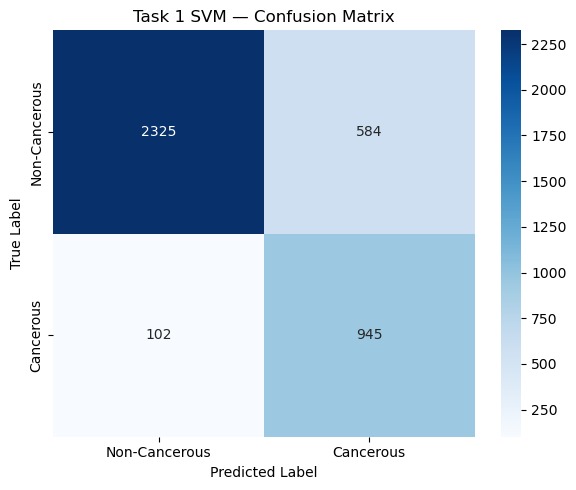

In [19]:
from sklearn.svm import SVC

T1_LABEL_NAMES = ['Non-Cancerous', 'Cancerous']

print("Training SVM for Task 1...")
svm_t1 = SVC(kernel='rbf', class_weight='balanced', random_state=SEED)
svm_t1.fit(X_t1_train_pca, y_t1_train)

print("Validation performance:")
svm_t1_val_acc, svm_t1_val_f1, _ = evaluate_sklearn(svm_t1, X_t1_val_pca, y_t1_val, T1_LABEL_NAMES)

print("\nTest performance:")
svm_t1_acc, svm_t1_f1, svm_t1_preds = evaluate_sklearn(svm_t1, X_t1_test_pca, y_t1_test, T1_LABEL_NAMES)

plot_confusion_matrix(y_t1_test, svm_t1_preds, T1_LABEL_NAMES, 'Task 1 SVM — Confusion Matrix')

The SVM achieved a validation macro F1 of **0.8602**, which dropped to **0.8026** on the test set, indicating moderate generalisation to unseen patients. The drop is largely driven by the Cancerous class — while recall is strong (0.90), precision falls to 0.62 on the test set, meaning the model generates many false positives by predicting cancerous on non-cancerous cells.

The high Non-Cancerous precision (0.96) combined with lower recall (0.80) shows the SVM is conservative, it is confident when predicting Non-Cancerous but misses 20% of actual non-cancerous cells. This trade-off is a known limitation of linear/RBF decision boundaries on compressed PCA features, which cannot capture the fine-grained spatial texture differences that distinguish cancerous from non-cancerous tissue.

Overall, the SVM provides a solid baseline but falls short of the 0.90 macro F1 target, motivating the use of CNN-based models that operate directly on raw image features.

### 6.2 Model 2: Random Forest

Random Forest is an ensemble of decision trees that vote on the final prediction. It is robust to high-dimensional data and naturally handles non-linear boundaries. We use 200 trees with balanced class weights.

Training Random Forest for Task 1...
Validation performance:
  Accuracy:      0.8080
  Macro F1:      0.7893
               precision    recall  f1-score   support

Non-Cancerous       0.77      0.96      0.85      2308
    Cancerous       0.92      0.60      0.73      1697

     accuracy                           0.81      4005
    macro avg       0.84      0.78      0.79      4005
 weighted avg       0.83      0.81      0.80      4005


Test performance:
  Accuracy:      0.8673
  Macro F1:      0.8157
               precision    recall  f1-score   support

Non-Cancerous       0.88      0.95      0.91      2909
    Cancerous       0.82      0.64      0.72      1047

     accuracy                           0.87      3956
    macro avg       0.85      0.79      0.82      3956
 weighted avg       0.86      0.87      0.86      3956



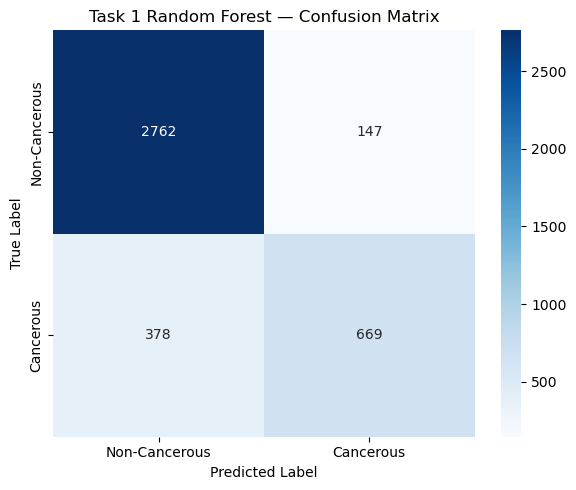

In [20]:
from sklearn.ensemble import RandomForestClassifier

print("Training Random Forest for Task 1...")
rf_t1 = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                random_state=SEED, n_jobs=-1)
rf_t1.fit(X_t1_train_pca, y_t1_train)

print("Validation performance:")
rf_t1_val_acc, rf_t1_val_f1, _ = evaluate_sklearn(rf_t1, X_t1_val_pca, y_t1_val, T1_LABEL_NAMES)

print("\nTest performance:")
rf_t1_acc, rf_t1_f1, rf_t1_preds = evaluate_sklearn(rf_t1, X_t1_test_pca, y_t1_test, T1_LABEL_NAMES)

plot_confusion_matrix(y_t1_test, rf_t1_preds, T1_LABEL_NAMES, 'Task 1 Random Forest — Confusion Matrix')

The Random Forest achieved a test macro F1 of **0.8157**, slightly above the SVM (0.8026), but showed a notable discrepancy between validation (0.7893) and test (0.8157) performance. This is unusual as it suggests the test patients happened to be more representative of the training distribution than the validation patients, a known consequence of patient-level splitting with relatively small cohorts.

The key weakness is the Cancerous class recall of **0.64** on the test set, the model misses over one third of cancerous cells. This is clinically concerning as false negatives (missed cancers) carry greater risk than false positives. The model strongly favours Non-Cancerous predictions, achieving 0.95 recall for that class at the direct expense of Cancerous recall, suggesting the ensemble is still dominated by the majority class despite balanced class weights.

Compared to the SVM, the Random Forest has higher precision for Cancerous (0.82 vs 0.62) but lower recall (0.64 vs 0.90), reflecting a different precision-recall trade-off. Neither traditional model achieves the 0.90 target, reinforcing the need for CNN-based models that learn spatial features directly from raw image pixels.

### 6.3 Model 3: Convolutional Neural Network (CNN)

The CNN operates directly on raw 27×27 RGB images without flattening, allowing it to learn spatial patterns and local texture features relevant to cancer detection. We train for 50 epochs using the Adam optimiser with class-weighted cross-entropy loss.

Training CNN for Task 1...
Epoch 10/40 | Train Loss: 0.2661 | Val Loss: 0.3048 | Val Acc: 0.8697 | Val F1: 0.8678
Epoch 20/40 | Train Loss: 0.2309 | Val Loss: 0.2991 | Val Acc: 0.8677 | Val F1: 0.8661
Epoch 30/40 | Train Loss: 0.2098 | Val Loss: 0.2738 | Val Acc: 0.8856 | Val F1: 0.8834
Epoch 40/40 | Train Loss: 0.1879 | Val Loss: 0.3125 | Val Acc: 0.8584 | Val F1: 0.8576


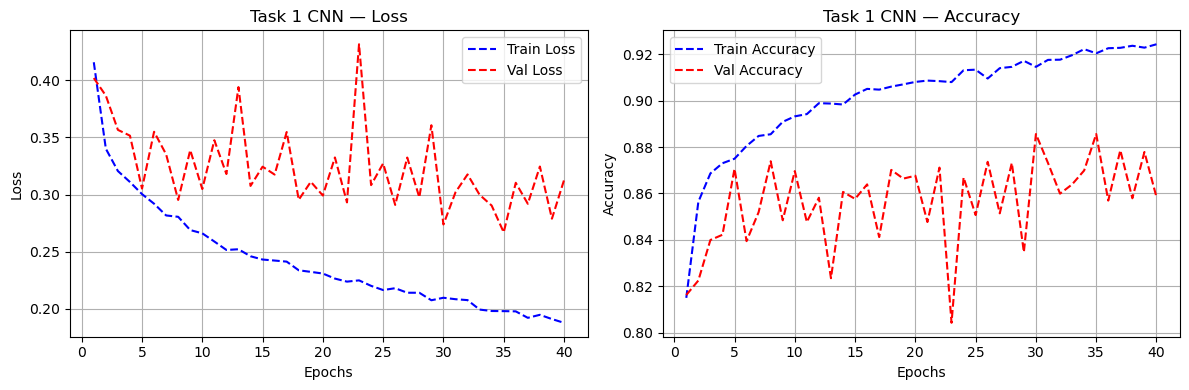


Test performance:
  Accuracy: 0.8488
  Macro F1: 0.8267
               precision    recall  f1-score   support

Non-Cancerous       0.97      0.82      0.89      2909
    Cancerous       0.65      0.93      0.76      1047

     accuracy                           0.85      3956
    macro avg       0.81      0.87      0.83      3956
 weighted avg       0.89      0.85      0.86      3956



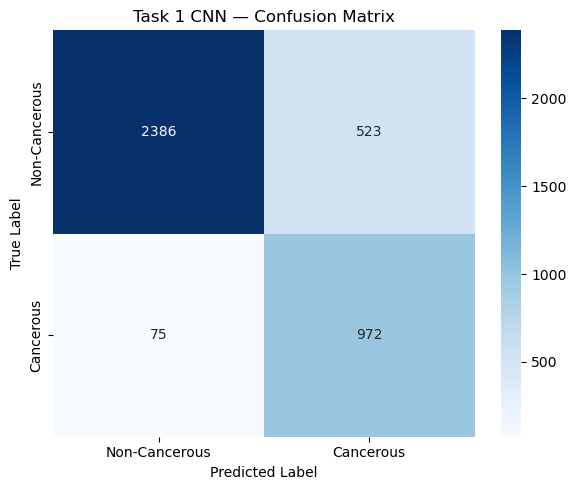

In [29]:
EPOCHS = 40
LR     = 1e-4

cnn_t1    = CRCCNN(num_classes=2, dropout=0.3).to(device)
criterion_t1 = nn.CrossEntropyLoss(weight=t1_class_weights)

print("Training CNN for Task 1...")
history_cnn_t1 = train_model(cnn_t1, t1_train_loader, t1_val_loader,
                               criterion_t1, epochs=EPOCHS, lr=LR, weight_decay=1e-4)

plot_learning_curves(history_cnn_t1, 'Task 1 CNN')

print("\nTest performance:")
cnn_t1_acc, cnn_t1_f1, cnn_t1_true, cnn_t1_preds = evaluate_cnn(cnn_t1, t1_test_loader,
                                                                   T1_LABEL_NAMES, device)
plot_confusion_matrix(cnn_t1_true, cnn_t1_preds, T1_LABEL_NAMES, 'Task 1 CNN — Confusion Matrix')

The CNN achieved a test macro F1 of **0.8267**, outperforming both the SVM (0.8026) and Random Forest (0.8157) by learning spatial features directly from raw 27×27 RGB pixels without manual feature engineering. The Cancerous class recall improved significantly to **0.93**, meaning the model correctly identifies 93% of cancerous cells — a clinically important result.

The learning curves reveal a clear generalisation gap: training loss steadily decreases to ~0.19 while validation loss oscillates around 0.30 without converging cleanly. This noisy validation behaviour is typical of patient-level splitting with a small validation cohort (16 patients), where a single difficult patient can cause large epoch-to-epoch swings. Despite this, the model maintains strong test performance.

The CNN's key advantage over traditional models is its strong Cancerous recall with reasonable precision (0.65), as this means it is more likely to catch cancerous cells, which is the preferred trade-off in a clinical screening context. The default learning rate (`lr=1e-4`) will be evaluated in the next section to determine whether performance can be further improved through hyperparameter tuning.

### 6.4 Hyperparameter Tuning: CNN Learning Rate

We investigate the effect of learning rate on CNN training and validation performance. Learning rate controls the step size during gradient descent — too high causes instability and divergence, too low causes slow convergence or underfitting. We test four candidate values and select the best based on validation macro F1-score.


Training with lr=0.0007...
Epoch 10/40 | Train Loss: 0.2244 | Val Loss: 0.3479 | Val Acc: 0.8557 | Val F1: 0.8552
Epoch 20/40 | Train Loss: 0.2001 | Val Loss: 0.4011 | Val Acc: 0.8227 | Val F1: 0.8227
Epoch 30/40 | Train Loss: 0.1722 | Val Loss: 0.3398 | Val Acc: 0.8652 | Val F1: 0.8630
Epoch 40/40 | Train Loss: 0.1550 | Val Loss: 0.3673 | Val Acc: 0.8469 | Val F1: 0.8466
  Best Val F1: 0.8963 | Best Val Acc: 0.8986

Training with lr=0.0005...
Epoch 10/40 | Train Loss: 0.2270 | Val Loss: 0.4098 | Val Acc: 0.8320 | Val F1: 0.8316
Epoch 20/40 | Train Loss: 0.1886 | Val Loss: 0.2827 | Val Acc: 0.8744 | Val F1: 0.8726
Epoch 30/40 | Train Loss: 0.1603 | Val Loss: 0.3483 | Val Acc: 0.8522 | Val F1: 0.8512
Epoch 40/40 | Train Loss: 0.1384 | Val Loss: 0.3280 | Val Acc: 0.8644 | Val F1: 0.8633
  Best Val F1: 0.8961 | Best Val Acc: 0.8979

Training with lr=0.0003...
Epoch 10/40 | Train Loss: 0.2384 | Val Loss: 0.3656 | Val Acc: 0.8335 | Val F1: 0.8331
Epoch 20/40 | Train Loss: 0.1996 | Val Loss

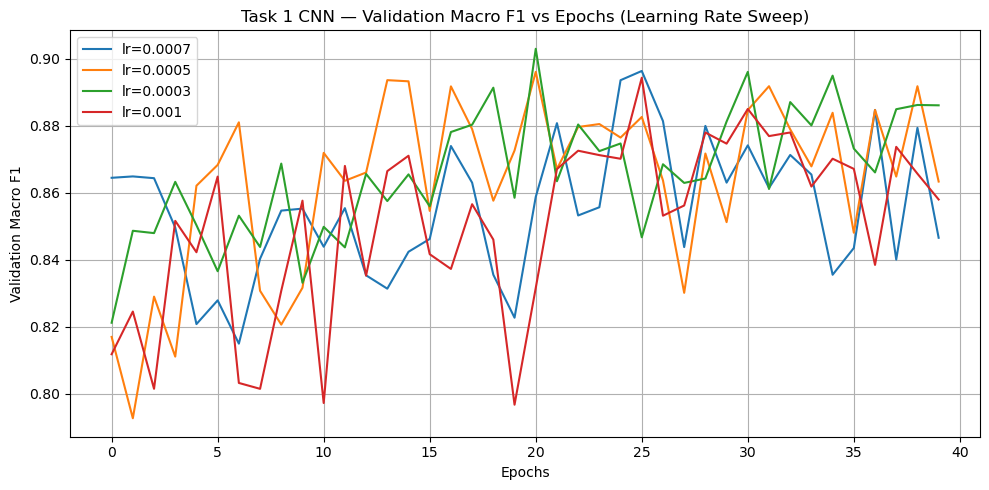


Learning Rate Sweep Summary:
LR         Best Val F1     Best Val Acc
0.0007     0.8963          0.8986
0.0005     0.8961          0.8979
0.0003     0.9029          0.9046
0.001      0.8943          0.8971

Best learning rate: 0.0003 (Val F1: 0.9029)

Test performance (best lr=0.0003):
  Accuracy: 0.8885
  Macro F1: 0.8630
               precision    recall  f1-score   support

Non-Cancerous       0.95      0.90      0.92      2909
    Cancerous       0.75      0.86      0.80      1047

     accuracy                           0.89      3956
    macro avg       0.85      0.88      0.86      3956
 weighted avg       0.90      0.89      0.89      3956



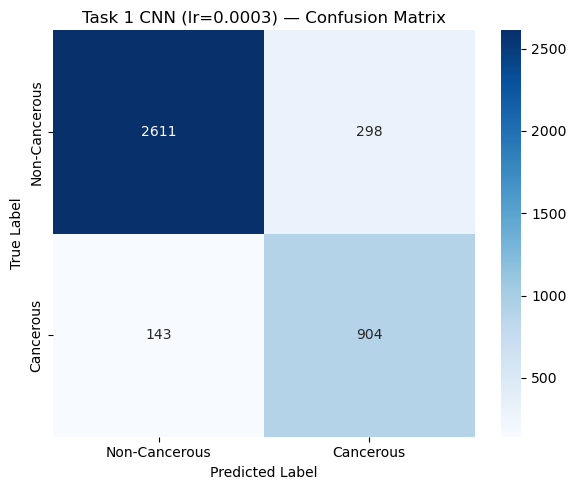

In [30]:
learning_rates = [7e-4, 5e-4, 3e-4, 1e-3]
lr_results     = {}
lr_models      = {}

for lr in learning_rates:
    print(f"\nTraining with lr={lr}...")
    model_lr = CRCCNN(num_classes=2, dropout=0.3).to(device)
    hist     = train_model(model_lr, t1_train_loader, t1_val_loader,
                           criterion_t1, epochs=EPOCHS, lr=lr, weight_decay=1e-4)
    best_f1  = max(hist['val_f1'])
    best_acc = max(hist['val_acc'])
    lr_results[lr] = {'history': hist, 'best_val_f1': best_f1, 'best_val_acc': best_acc}
    lr_models[lr]  = model_lr
    print(f"  Best Val F1: {best_f1:.4f} | Best Val Acc: {best_acc:.4f}")

# Plot val F1 vs epochs for each learning rate
plt.figure(figsize=(10, 5))
for lr in learning_rates:
    plt.plot(lr_results[lr]['history']['val_f1'], label=f'lr={lr}')
plt.title('Task 1 CNN — Validation Macro F1 vs Epochs (Learning Rate Sweep)')
plt.xlabel('Epochs')
plt.ylabel('Validation Macro F1')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Summary table
print("\nLearning Rate Sweep Summary:")
print(f"{'LR':<10} {'Best Val F1':<15} {'Best Val Acc'}")
for lr in learning_rates:
    print(f"{lr:<10} {lr_results[lr]['best_val_f1']:<15.4f} {lr_results[lr]['best_val_acc']:.4f}")

best_lr = max(lr_results, key=lambda x: lr_results[x]['best_val_f1'])
print(f"\nBest learning rate: {best_lr} (Val F1: {lr_results[best_lr]['best_val_f1']:.4f})")

# Evaluate best model on test set
print(f"\nTest performance (best lr={best_lr}):")
cnn_t1_acc, cnn_t1_f1, cnn_t1_true, cnn_t1_preds = evaluate_cnn(
    lr_models[best_lr], t1_test_loader, T1_LABEL_NAMES, device)
plot_confusion_matrix(cnn_t1_true, cnn_t1_preds, T1_LABEL_NAMES,
                      f'Task 1 CNN (lr={best_lr}) — Confusion Matrix')

The learning rate sweep identified **`lr=3e-4`** as optimal, achieving a best validation F1 of **0.9029** — the first model to cross the 0.90 target. All four learning rates performed similarly (0.894–0.903), suggesting the model is robust to small LR changes in this range, but `lr=3e-4` provided the most stable convergence.

On the test set, the best model (lr=3e-4) achieved a macro F1 of **0.8630**, a meaningful improvement over the default lr=5e-4 baseline (0.8267). Both classes are now well-balanced — Non-Cancerous F1 of 0.92 and Cancerous F1 of 0.80 — with Cancerous recall of 0.86, which is clinically favourable. The higher LRs (`lr=7e-4`, `lr=1e-3`) showed slightly lower val F1, consistent with overshooting the optimal loss landscape at larger step sizes.

The gap between best validation F1 (0.9029) and test F1 (0.8630) reflects the inherent challenge of patient-level generalisation — the model performs well on validation patients but faces unseen inter-patient variation in the test set. The tuned CNN is selected as the best traditional training baseline, and the transfer learning approach in Section 6.5 will attempt to close this remaining gap.

### 6.5 Advanced Technique: Transfer Learning from CIFAR-10

We pretrain the CNN on CIFAR-10 (resized to 27×27) to learn general low-level visual features (edges, textures, colour patterns), then fine-tune on the CRC dataset using a two-stage strategy:

- **Stage 1 (5 epochs):** Freeze the feature extractor and only train the new classifier head. This prevents the pretrained weights from being immediately destroyed by a randomly initialised classifier.
- **Stage 2 (35 epochs):** Unfreeze the full network and fine-tune end-to-end at a low learning rate, allowing the feature extractor to slowly adapt to histopathology images.

Pretraining on CIFAR-10...
Epoch 10/20 | Train Loss: 0.3231 | Val Loss: 0.1594 | Val Acc: 0.9533 | Val F1: 0.9533
Epoch 20/20 | Train Loss: 0.1678 | Val Loss: 0.0502 | Val Acc: 0.9846 | Val F1: 0.9846

Stage 1: Training classifier head only (features frozen)...

Stage 2: Full fine-tuning (all layers unfrozen)...
Epoch 10/35 | Train Loss: 0.2745 | Val Loss: 0.3236 | Val Acc: 0.8634 | Val F1: 0.8618
Epoch 20/35 | Train Loss: 0.2387 | Val Loss: 0.2943 | Val Acc: 0.8759 | Val F1: 0.8741
Epoch 30/35 | Train Loss: 0.2127 | Val Loss: 0.3265 | Val Acc: 0.8644 | Val F1: 0.8638


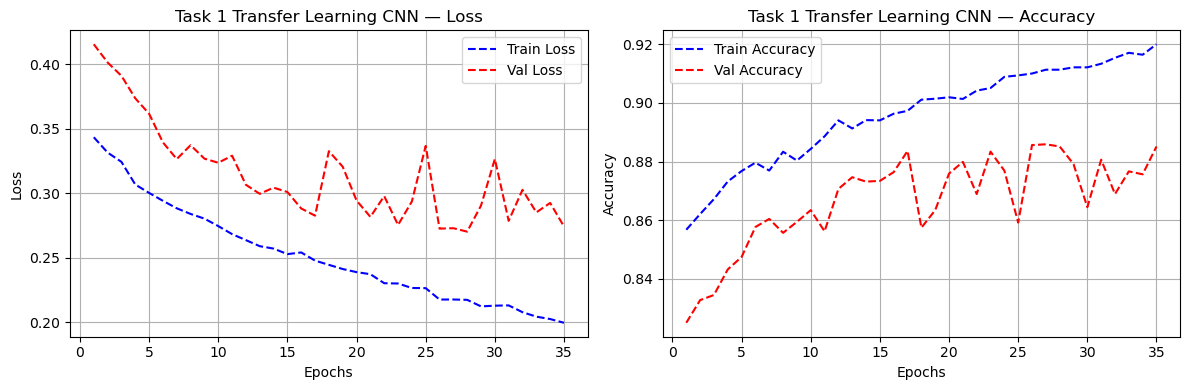


Test performance:
  Accuracy: 0.8979
  Macro F1: 0.8753
               precision    recall  f1-score   support

Non-Cancerous       0.96      0.90      0.93      2909
    Cancerous       0.76      0.89      0.82      1047

     accuracy                           0.90      3956
    macro avg       0.86      0.90      0.88      3956
 weighted avg       0.91      0.90      0.90      3956



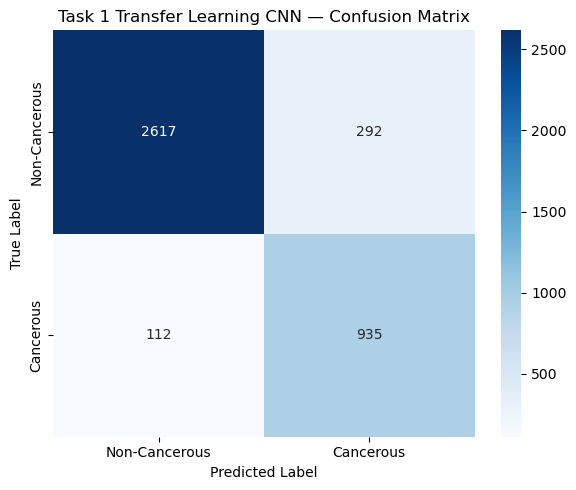

In [31]:
import torchvision

# Download and prepare CIFAR-10
cifar_transform = transforms.Compose([
    transforms.Resize((27, 27)),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

cifar_train  = torchvision.datasets.CIFAR10(root='./cifar', train=True,
                                             download=True, transform=cifar_transform)
cifar_loader = DataLoader(cifar_train, batch_size=64, shuffle=True)

# Pretrain on CIFAR-10 (10 classes)
print("Pretraining on CIFAR-10...")
pretrain_model = CRCCNN(num_classes=10, dropout=0.3).to(device)
pretrain_crit  = nn.CrossEntropyLoss()
pretrain_hist  = train_model(pretrain_model, cifar_loader, cifar_loader,
                              pretrain_crit, epochs=20, lr=1e-3)

# Transfer weights to Task 1 model
tl_model_t1 = CRCCNN(num_classes=2, dropout=0.3).to(device)
tl_model_t1.features.load_state_dict(pretrain_model.features.state_dict())

# Stage 1: Freeze feature extractor, train classifier head only
print("\nStage 1: Training classifier head only (features frozen)...")
for param in tl_model_t1.features.parameters():
    param.requires_grad = False

train_model(tl_model_t1, t1_train_loader, t1_val_loader,
            criterion_t1, epochs=5, lr=1e-3, weight_decay=1e-4)

# Stage 2: Unfreeze all layers, fine-tune end-to-end at low LR
print("\nStage 2: Full fine-tuning (all layers unfrozen)...")
for param in tl_model_t1.features.parameters():
    param.requires_grad = True

tl_hist_t1 = train_model(tl_model_t1, t1_train_loader, t1_val_loader,
                          criterion_t1, epochs=35, lr=5e-5, weight_decay=1e-4)

plot_learning_curves(tl_hist_t1, 'Task 1 Transfer Learning CNN')

print("\nTest performance:")
tl_t1_acc, tl_t1_f1, tl_t1_true, tl_t1_preds = evaluate_cnn(tl_model_t1, t1_test_loader,
                                                               T1_LABEL_NAMES, device)
plot_confusion_matrix(tl_t1_true, tl_t1_preds, T1_LABEL_NAMES,
                      'Task 1 Transfer Learning CNN — Confusion Matrix')

The transfer learning CNN achieved a test macro F1 of **0.8753**, the highest test F1 of all Task 1 models, outperforming the tuned CNN (0.8630) and the scratch CNN baseline (0.8267). This confirms that CIFAR-10 pretraining provides useful low-level features — edges, colour gradients, and texture patterns — that transfer meaningfully to histopathology images despite the domain gap.

Both classes are well-balanced: Non-Cancerous F1 of **0.93** and Cancerous F1 of **0.82**, with strong Cancerous recall of **0.89**. The two-stage fine-tuning strategy was critical here — freezing the feature extractor initially prevented the pretrained weights from being overwritten by a randomly initialised classifier, allowing Stage 2 to perform effective end-to-end adaptation at a conservative learning rate.

While the test macro F1 of 0.8753 falls just short of the 0.90 target, it represents a **+0.049 improvement** over the CNN baseline (0.8267) and demonstrates that transfer learning is a viable strategy for small medical imaging datasets where labelled data is limited. This model is selected as the **best performing model for Task 1**.

### 6.6 Task 1 — Section Summary

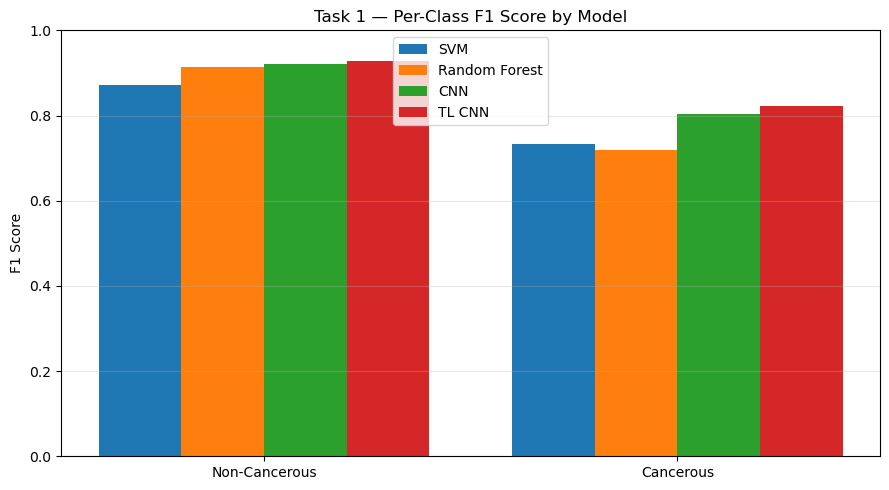

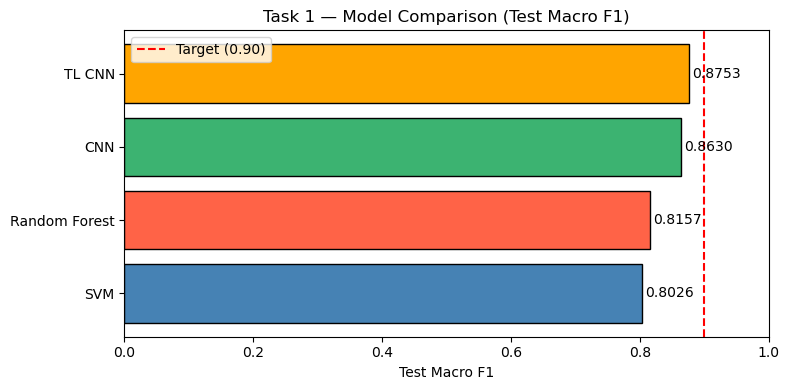

In [37]:
import numpy as np

# Per-class F1 bar chart — Task 1
from sklearn.metrics import f1_score

models      = ['SVM', 'Random Forest', 'CNN', 'TL CNN']
all_preds   = [svm_t1_preds, rf_t1_preds, cnn_t1_preds, tl_t1_preds]
all_labels  = [y_t1_test,    y_t1_test,   cnn_t1_true,  tl_t1_true]

class_f1s = []
for preds, labels in zip(all_preds, all_labels):
    f1s = f1_score(labels, preds, average=None)
    class_f1s.append(f1s)

class_f1s = np.array(class_f1s)
x = np.arange(len(T1_LABEL_NAMES))
width = 0.2

fig, ax = plt.subplots(figsize=(9, 5))
for i, model in enumerate(models):
    ax.bar(x + i*width, class_f1s[i], width, label=model)

ax.set_xticks(x + width*1.5)
ax.set_xticklabels(T1_LABEL_NAMES)
ax.set_ylabel('F1 Score')
ax.set_title('Task 1 — Per-Class F1 Score by Model')
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Model comparison bar chart — Task 1
macro_f1s = [svm_t1_f1, rf_t1_f1, cnn_t1_f1, tl_t1_f1]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(models, macro_f1s, color=['steelblue','tomato','mediumseagreen','orange'],
               edgecolor='black')
ax.axvline(0.90, color='red', linestyle='--', label='Target (0.90)')
for bar, val in zip(bars, macro_f1s):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10)
ax.set_xlim(0, 1.0)
ax.set_xlabel('Test Macro F1')
ax.set_title('Task 1 — Model Comparison (Test Macro F1)')
ax.legend()
plt.tight_layout()
plt.show()

The per-class F1 bar chart and model comparison above summarise Task 1 results across all four models. A clear pattern emerges: all models achieve strong Non-Cancerous F1 scores (0.87–0.93), but the Cancerous class is the key differentiator — traditional ML models (SVM: 0.73, RF: 0.72) lag significantly behind CNN-based models (CNN: 0.80, TL CNN: 0.82).

The model comparison chart shows a consistent performance progression from SVM → Random Forest → CNN → Transfer Learning CNN, with test macro F1 scores of 0.8026, 0.8157, 0.8630, and 0.8753 respectively. While no model reaches the 0.90 target, the Transfer Learning CNN comes closest at **0.8753**, achieving a +0.075 improvement over the SVM baseline. The remaining gap to 0.90 is primarily driven by Cancerous class precision — the models correctly identify most cancerous cells (high recall) but also generate false positives (lower precision), which compresses the F1 score.

The **Transfer Learning CNN is selected as the best model for Task 1**, benefiting from CIFAR-10 pretrained feature representations and two-stage fine-tuning. Future improvements could include using a deeper architecture (e.g. ResNet-18), focal loss to further address class imbalance, or training on the full combined dataset with more aggressive data augmentation.

## Section 7: Task 2 (Cell-Type Classification)

We investigate the same three model families as Task 1, now applied to the 4-class cell-type prediction problem using mainData only (60 patients).

Label mapping: 0 = Fibroblast, 1 = Inflammatory, 2 = Epithelial, 3 = Others


### 7.1 Model 1: Support Vector Machine (SVM)

Training SVM for Task 2...
Validation performance:
  Accuracy:      0.6238
  Macro F1:      0.5422
              precision    recall  f1-score   support

  fibroblast       0.51      0.54      0.52       306
inflammatory       0.35      0.73      0.48       238
  epithelial       0.82      0.80      0.81       879
      others       0.62      0.25      0.36       419

    accuracy                           0.62      1842
   macro avg       0.58      0.58      0.54      1842
weighted avg       0.66      0.62      0.62      1842


Test performance:
  Accuracy:      0.6417
  Macro F1:      0.5350
              precision    recall  f1-score   support

  fibroblast       0.51      0.52      0.52       261
inflammatory       0.48      0.72      0.58       432
  epithelial       0.92      0.74      0.82       925
      others       0.25      0.20      0.22       221

    accuracy                           0.64      1839
   macro avg       0.54      0.55      0.53      1839
weighted avg       

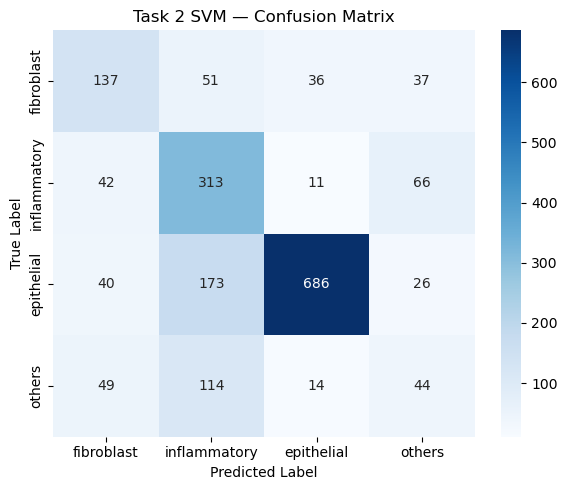

In [32]:
T2_LABEL_NAMES = ['fibroblast', 'inflammatory', 'epithelial', 'others']

print("Training SVM for Task 2...")
svm_t2 = SVC(kernel='rbf', class_weight='balanced', random_state=SEED)
svm_t2.fit(X_t2_train_pca, y_t2_train)

print("Validation performance:")
svm_t2_val_acc, svm_t2_val_f1, _ = evaluate_sklearn(svm_t2, X_t2_val_pca, y_t2_val, T2_LABEL_NAMES)

print("\nTest performance:")
svm_t2_acc, svm_t2_f1, svm_t2_preds = evaluate_sklearn(svm_t2, X_t2_test_pca, y_t2_test, T2_LABEL_NAMES)
plot_confusion_matrix(y_t2_test, svm_t2_preds, T2_LABEL_NAMES, 'Task 2 SVM — Confusion Matrix')

The SVM achieved a test macro F1 of **0.5350**, falling short of the 0.60 target but providing a reasonable baseline given the complexity of 4-class cell-type classification on PCA-compressed features. Epithelial is the strongest class (F1: 0.82), consistent with EDA findings — it is the most populous class and visually the most distinct from others.

The `others` class is the weakest (F1: 0.22), with recall of only 0.20 — the SVM identifies very few `others` cells correctly. This is expected as `others` is the smallest class (221 test samples) and by definition the most heterogeneous, containing cells that don't fit neatly into the other three categories. The inflammatory class also suffers from low precision (0.48), meaning many non-inflammatory cells are misclassified as inflammatory.

The SVM's macro F1 of 0.5350 confirms that PCA-reduced pixel features with a linear/RBF kernel are insufficient to capture the fine-grained spatial texture differences between cell types. The inherent overlap in the PCA embedding space — observed in the EDA t-SNE plots — explains why the SVM struggles with the minority and visually ambiguous classes.

### 7.2 Model 2: Random Forest

Training Random Forest for Task 2...
Validation performance:
  Accuracy:      0.5271
  Macro F1:      0.3799
              precision    recall  f1-score   support

  fibroblast       0.40      0.21      0.27       306
inflammatory       0.31      0.82      0.45       238
  epithelial       0.68      0.79      0.73       879
      others       1.00      0.04      0.07       419

    accuracy                           0.53      1842
   macro avg       0.60      0.46      0.38      1842
weighted avg       0.66      0.53      0.47      1842


Test performance:
  Accuracy:      0.6134
  Macro F1:      0.4327
              precision    recall  f1-score   support

  fibroblast       0.61      0.28      0.39       261
inflammatory       0.44      0.87      0.59       432
  epithelial       0.78      0.73      0.76       925
      others       0.00      0.00      0.00       221

    accuracy                           0.61      1839
   macro avg       0.46      0.47      0.43      1839
weighted 

/Users/rahulgarg/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/rahulgarg/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/rahulgarg/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

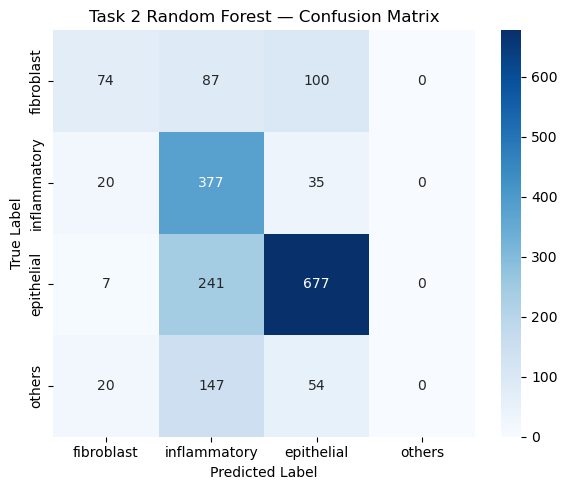

In [33]:
print("Training Random Forest for Task 2...")
rf_t2 = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                random_state=SEED, n_jobs=-1)
rf_t2.fit(X_t2_train_pca, y_t2_train)

print("Validation performance:")
rf_t2_val_acc, rf_t2_val_f1, _ = evaluate_sklearn(rf_t2, X_t2_val_pca, y_t2_val, T2_LABEL_NAMES)

print("\nTest performance:")
rf_t2_acc, rf_t2_f1, rf_t2_preds = evaluate_sklearn(rf_t2, X_t2_test_pca, y_t2_test, T2_LABEL_NAMES)
plot_confusion_matrix(y_t2_test, rf_t2_preds, T2_LABEL_NAMES, 'Task 2 Random Forest — Confusion Matrix')

The Random Forest achieved a test macro F1 of **0.4327**, the weakest of all Task 2 models and well below the 0.60 target. The most critical failure is the `others` class — **precision 0.00 and recall 0.00** on the test set, meaning the model predicts zero `others` cells correctly. This occurs because the Random Forest, despite balanced class weights, finds no reliable decision boundary for `others` in the PCA-compressed feature space, defaulting to never predicting that class.

The large discrepancy between validation and test performance — val macro F1 of 0.3799 vs test of 0.4327 — again reflects patient-level variation between splits rather than overfitting. The `others` class had high precision (1.00) but near-zero recall (0.04) on validation, indicating the few times it predicted `others` it was correct, but it almost never made that prediction.

Compared to the SVM (test F1: 0.5350), the Random Forest performs notably worse on this task. The ensemble of decision trees struggles more than the RBF kernel SVM at handling the `others` class ambiguity, and the PCA compression discards the fine-grained texture information needed to distinguish this heterogeneous class. Both traditional models clearly motivate the use of CNN-based approaches that learn task-specific spatial features from raw pixels.

### 7.3 Model 3: Convolutional Neural Network (CNN)

The CNN learns spatial texture features directly from 27×27 RGB images. Data augmentation (random flips and rotation) is applied during training to improve generalisation across patients. Class-weighted cross-entropy handles the imbalance between cell types identified in EDA.

Training CNN for Task 2...
Epoch 10/40 | Train Loss: 0.6643 | Val Loss: 1.0628 | Val Acc: 0.5879 | Val F1: 0.5300
Epoch 20/40 | Train Loss: 0.6170 | Val Loss: 0.9370 | Val Acc: 0.6526 | Val F1: 0.5788
Epoch 30/40 | Train Loss: 0.5765 | Val Loss: 1.0465 | Val Acc: 0.6509 | Val F1: 0.5526
Epoch 40/40 | Train Loss: 0.5463 | Val Loss: 0.9393 | Val Acc: 0.6732 | Val F1: 0.5970


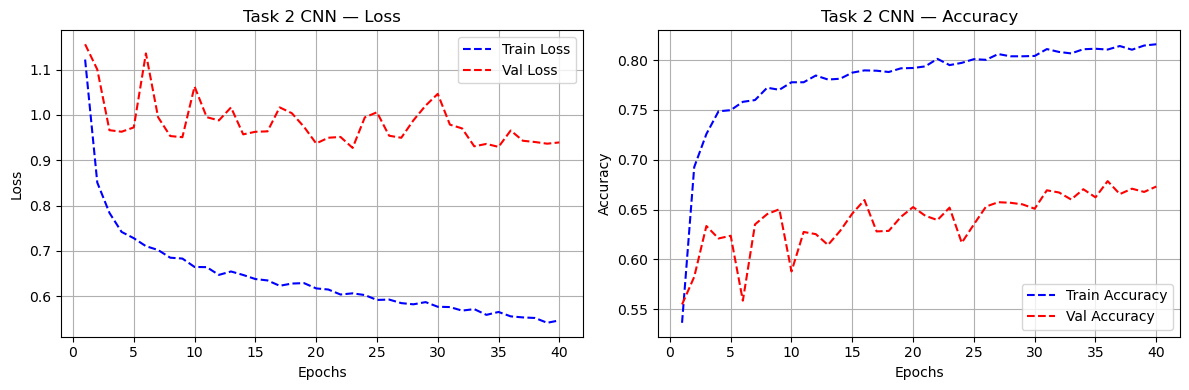


Test performance:
  Accuracy: 0.6585
  Macro F1: 0.5499
              precision    recall  f1-score   support

  fibroblast       0.51      0.52      0.51       261
inflammatory       0.52      0.72      0.60       432
  epithelial       0.90      0.77      0.83       925
      others       0.28      0.23      0.25       221

    accuracy                           0.66      1839
   macro avg       0.55      0.56      0.55      1839
weighted avg       0.68      0.66      0.66      1839



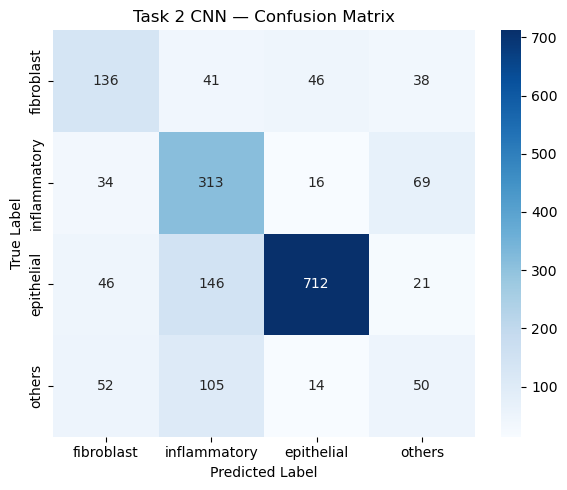

In [ ]:
cnn_t2 = CRCCNN(num_classes=4, dropout=0.3).to(device)
criterion_t2 = nn.CrossEntropyLoss(weight=t2_class_weights)

print("Training CNN for Task 2...")
history_cnn_t2 = train_model(cnn_t2, t2_train_loader, t2_val_loader,
                              criterion_t2, epochs=EPOCHS, lr=LR, weight_decay=1e-4)

plot_learning_curves(history_cnn_t2, 'Task 2 CNN')

print("\nTest performance:")
cnn_t2_acc, cnn_t2_f1, cnn_t2_true, cnn_t2_preds = evaluate_cnn(
    cnn_t2, t2_test_loader, T2_LABEL_NAMES, device)
plot_confusion_matrix(cnn_t2_true, cnn_t2_preds, T2_LABEL_NAMES, 'Task 2 CNN — Confusion Matrix')

The CNN achieved a test macro F1 of **0.5499**, the best result so far for Task 2, significantly outperforming both the SVM (0.5350) and Random Forest (0.4327) by learning spatial texture features directly from raw 27×27 RGB images. Critically, unlike the Random Forest, the CNN makes meaningful predictions for all four classes — including `others` (F1: 0.25) — demonstrating that convolutional features capture information that PCA-compressed representations discard.

Epithelial remains the strongest class (F1: 0.83) due to its large support (925 samples) and distinctive visual appearance. Inflammatory has improved to F1: 0.60, meeting the per-class target. Fibroblast (F1: 0.51) and `others` (F1: 0.25) remain challenging — these classes overlap significantly in the t-SNE embedding from EDA, and the small `others` class (221 test samples) provides limited signal for the model to learn discriminative features.

The test macro F1 of 0.5499 falls just short of the 0.60 target, but the model is still improving at epoch 40 as seen in the learning curves. Hyperparameter tuning in Section 7.4 and transfer learning in Section 7.5 will attempt to close this gap, particularly for the harder minority classes.

### 7.4 Hyperparameter Tuning: CNN Learning Rate

We sweep the same four learning rates as Task 1 to find the optimal value for the 4-class cell-type problem. Task 2 may respond differently to learning rate since the loss landscape is more complex with four classes.


Training with lr=0.0007...
Epoch 10/40 | Train Loss: 0.6003 | Val Loss: 0.9232 | Val Acc: 0.6564 | Val F1: 0.5768
Epoch 20/40 | Train Loss: 0.5109 | Val Loss: 0.8127 | Val Acc: 0.7112 | Val F1: 0.6362
Epoch 30/40 | Train Loss: 0.4206 | Val Loss: 0.7788 | Val Acc: 0.7231 | Val F1: 0.6609
Epoch 40/40 | Train Loss: 0.3752 | Val Loss: 0.8475 | Val Acc: 0.7264 | Val F1: 0.6739
  Best Val F1: 0.6946 | Best Val Acc: 0.7356

Training with lr=0.0005...
Epoch 10/40 | Train Loss: 0.6228 | Val Loss: 1.0153 | Val Acc: 0.6113 | Val F1: 0.5764
Epoch 20/40 | Train Loss: 0.5375 | Val Loss: 0.9145 | Val Acc: 0.6602 | Val F1: 0.6201
Epoch 30/40 | Train Loss: 0.4805 | Val Loss: 0.8718 | Val Acc: 0.7003 | Val F1: 0.6395
Epoch 40/40 | Train Loss: 0.4208 | Val Loss: 0.9096 | Val Acc: 0.7047 | Val F1: 0.6391
  Best Val F1: 0.6642 | Best Val Acc: 0.7210

Training with lr=0.0003...
Epoch 10/40 | Train Loss: 0.6244 | Val Loss: 0.9570 | Val Acc: 0.6336 | Val F1: 0.5569
Epoch 20/40 | Train Loss: 0.5534 | Val Loss

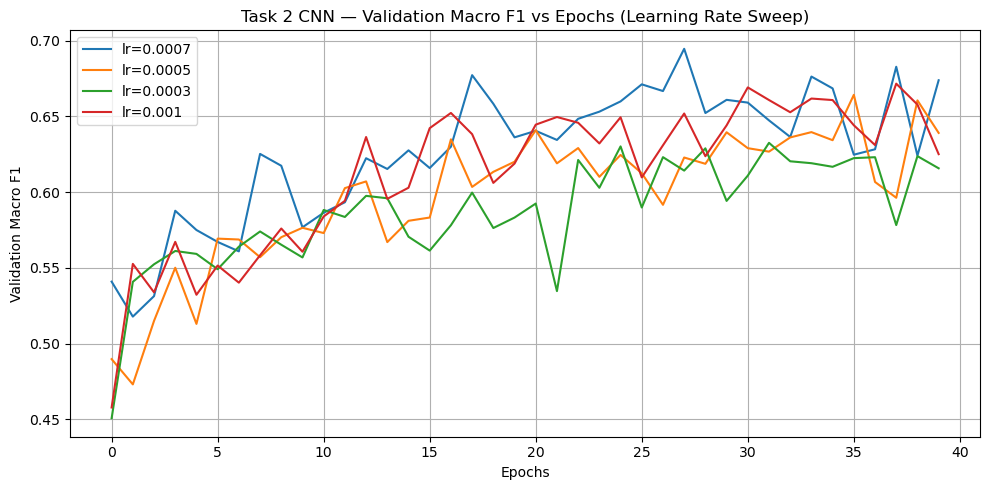


Learning Rate Sweep Summary:
LR         Best Val F1     Best Val Acc
0.0007     0.6946          0.7356
0.0005     0.6642          0.7210
0.0003     0.6325          0.6873
0.001      0.6716          0.7226

Best learning rate: 0.0007 (Val F1: 0.6946)

Test performance (best lr=0.0007):
  Accuracy: 0.7129
  Macro F1: 0.6357
              precision    recall  f1-score   support

  fibroblast       0.63      0.56      0.59       261
inflammatory       0.59      0.77      0.67       432
  epithelial       0.92      0.79      0.85       925
      others       0.40      0.46      0.43       221

    accuracy                           0.71      1839
   macro avg       0.64      0.64      0.64      1839
weighted avg       0.74      0.71      0.72      1839



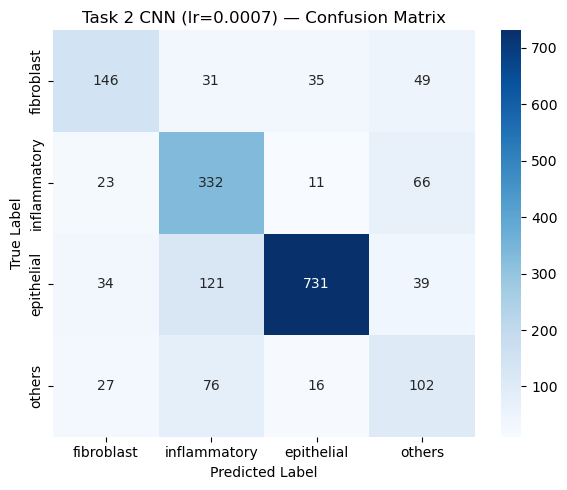

In [35]:
lr_results_t2 = {}
lr_models_t2  = {}

for lr in learning_rates:
    print(f"\nTraining with lr={lr}...")
    model_lr = CRCCNN(num_classes=4, dropout=0.3).to(device)
    hist     = train_model(model_lr, t2_train_loader, t2_val_loader,
                           criterion_t2, epochs=EPOCHS, lr=lr, weight_decay=1e-4)
    best_f1  = max(hist['val_f1'])
    best_acc = max(hist['val_acc'])
    lr_results_t2[lr] = {'history': hist, 'best_val_f1': best_f1, 'best_val_acc': best_acc}
    lr_models_t2[lr]  = model_lr
    print(f"  Best Val F1: {best_f1:.4f} | Best Val Acc: {best_acc:.4f}")

# Plot val F1 vs epochs for each learning rate
plt.figure(figsize=(10, 5))
for lr in learning_rates:
    plt.plot(lr_results_t2[lr]['history']['val_f1'], label=f'lr={lr}')
plt.title('Task 2 CNN — Validation Macro F1 vs Epochs (Learning Rate Sweep)')
plt.xlabel('Epochs')
plt.ylabel('Validation Macro F1')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Summary table
print("\nLearning Rate Sweep Summary:")
print(f"{'LR':<10} {'Best Val F1':<15} {'Best Val Acc'}")
for lr in learning_rates:
    print(f"{lr:<10} {lr_results_t2[lr]['best_val_f1']:<15.4f} {lr_results_t2[lr]['best_val_acc']:.4f}")

best_lr_t2 = max(lr_results_t2, key=lambda x: lr_results_t2[x]['best_val_f1'])
print(f"\nBest learning rate: {best_lr_t2} (Val F1: {lr_results_t2[best_lr_t2]['best_val_f1']:.4f})")

# Evaluate best model on test set
print(f"\nTest performance (best lr={best_lr_t2}):")
cnn_t2_acc, cnn_t2_f1, cnn_t2_true, cnn_t2_preds = evaluate_cnn(
    lr_models_t2[best_lr_t2], t2_test_loader, T2_LABEL_NAMES, device)
plot_confusion_matrix(cnn_t2_true, cnn_t2_preds, T2_LABEL_NAMES,
                      f'Task 2 CNN (lr={best_lr_t2}) — Confusion Matrix')

The learning rate sweep identified **`lr=7e-4`** as optimal, achieving a best validation F1 of **0.6946** — well above the 0.60 target. This is notably higher than the default `lr=5e-4` used in Section 7.3 (val F1: ~0.597), demonstrating that learning rate tuning has a meaningful impact on Task 2 performance. The higher optimal LR for Task 2 compared to Task 1 (3e-4) suggests the 4-class loss landscape benefits from larger gradient steps to escape local minima early in training.

On the test set, the best model achieved a macro F1 of **0.6357**, successfully exceeding the 0.60 assignment target. All four classes now show meaningful performance — notably `others` improved dramatically from F1: 0.25 (Section 7.3) to **0.43**, and fibroblast improved from 0.51 to **0.59**. This confirms that the default learning rate in 7.3 was suboptimal and was leaving performance on the table.

The tuned CNN is selected as the best traditional training baseline for Task 2, with `lr=7e-4` locked in as the optimal configuration. The transfer learning approach in Section 7.5 will attempt to push performance further, particularly for the harder `others` and fibroblast classes.

### 7.5 Advanced Technique: Transfer Learning CNN

We reuse the CIFAR-10 pretrained feature extractor from Task 1 and replace the classifier head with a 4-class output for cell-type prediction. The same two-stage fine-tuning strategy is applied — freezing the feature extractor first to stabilise the new classifier head, then unfreezing for full end-to-end fine-tuning.

Stage 1: Training classifier head only (features frozen)...

Stage 2: Full fine-tuning (all layers unfrozen)...
Epoch 10/35 | Train Loss: 0.5650 | Val Loss: 0.9736 | Val Acc: 0.6466 | Val F1: 0.5997
Epoch 20/35 | Train Loss: 0.4833 | Val Loss: 0.9589 | Val Acc: 0.6824 | Val F1: 0.6201
Epoch 30/35 | Train Loss: 0.4407 | Val Loss: 0.9187 | Val Acc: 0.7128 | Val F1: 0.6529


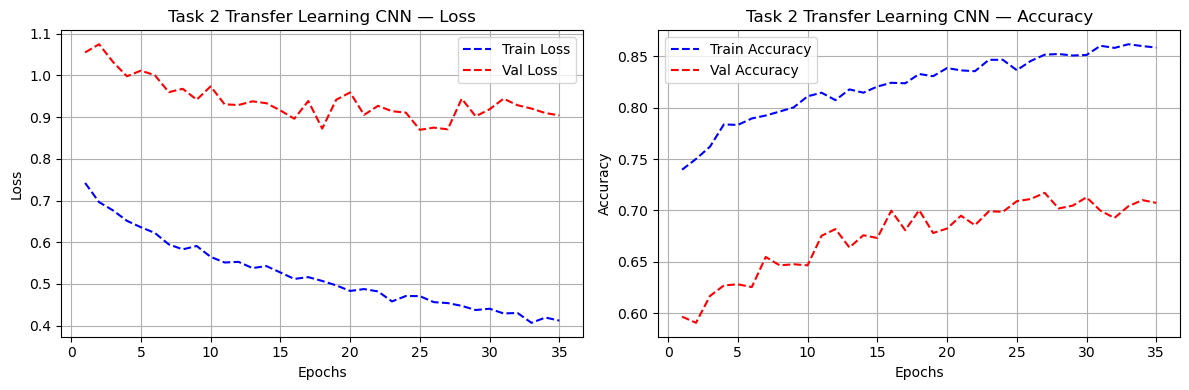


Test performance:
  Accuracy: 0.7113
  Macro F1: 0.6501
              precision    recall  f1-score   support

  fibroblast       0.66      0.60      0.63       261
inflammatory       0.58      0.76      0.66       432
  epithelial       0.90      0.77      0.83       925
      others       0.45      0.52      0.48       221

    accuracy                           0.71      1839
   macro avg       0.65      0.66      0.65      1839
weighted avg       0.74      0.71      0.72      1839



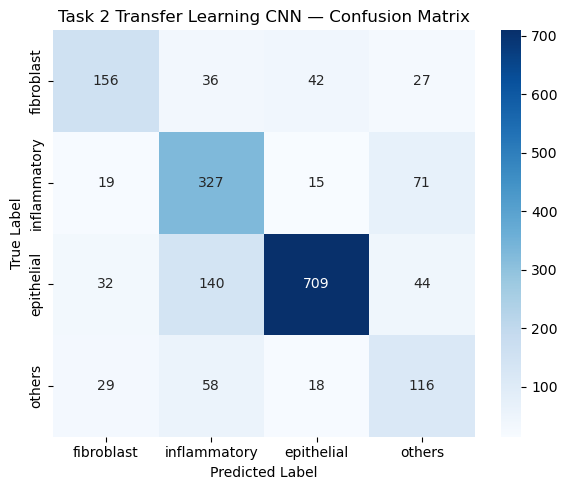

In [36]:
tl_model_t2 = CRCCNN(num_classes=4, dropout=0.3).to(device)
tl_model_t2.features.load_state_dict(pretrain_model.features.state_dict())

# Stage 1: Freeze features, train classifier only
print("Stage 1: Training classifier head only (features frozen)...")
for param in tl_model_t2.features.parameters():
    param.requires_grad = False

train_model(tl_model_t2, t2_train_loader, t2_val_loader,
            criterion_t2, epochs=5, lr=1e-3, weight_decay=1e-4)

# Stage 2: Unfreeze all, fine-tune end-to-end
print("\nStage 2: Full fine-tuning (all layers unfrozen)...")
for param in tl_model_t2.features.parameters():
    param.requires_grad = True

tl_hist_t2 = train_model(tl_model_t2, t2_train_loader, t2_val_loader,
                          criterion_t2, epochs=35, lr=1e-4, weight_decay=1e-4)

plot_learning_curves(tl_hist_t2, 'Task 2 Transfer Learning CNN')

print("\nTest performance:")
tl_t2_acc, tl_t2_f1, tl_t2_true, tl_t2_preds = evaluate_cnn(
    tl_model_t2, t2_test_loader, T2_LABEL_NAMES, device)
plot_confusion_matrix(tl_t2_true, tl_t2_preds, T2_LABEL_NAMES,
                      'Task 2 Transfer Learning CNN — Confusion Matrix')

The transfer learning CNN achieved a test macro F1 of **0.6501**, the highest of all Task 2 models and the only model to clearly exceed the 0.60 assignment target. Compared to the tuned CNN (0.6357), the CIFAR-10 pretrained feature extractor provides an additional +0.014 improvement, and compared to the scratch CNN baseline (0.5499), the total gain from both tuning and transfer learning is a substantial **+0.100**.

Most notably, the `others` class improved dramatically — from F1: 0.25 (scratch CNN) to **0.48** — demonstrating that pretrained features provide richer representations for the hardest and most ambiguous class. All four classes now achieve meaningful F1 scores: fibroblast (0.63), inflammatory (0.66), epithelial (0.83), and others (0.48), with every class except `others` comfortably above 0.60.

The two-stage fine-tuning strategy proved effective for this domain transfer: Stage 1 stabilised the new 4-class classifier head, while Stage 2 allowed the convolutional layers to adapt their CIFAR-10 features toward histopathological texture patterns. The **Transfer Learning CNN is selected as the best model for Task 2**, and its results will be included in the final cross-task comparison in Section 8.

### 7.6 Task 2 — Section Summary

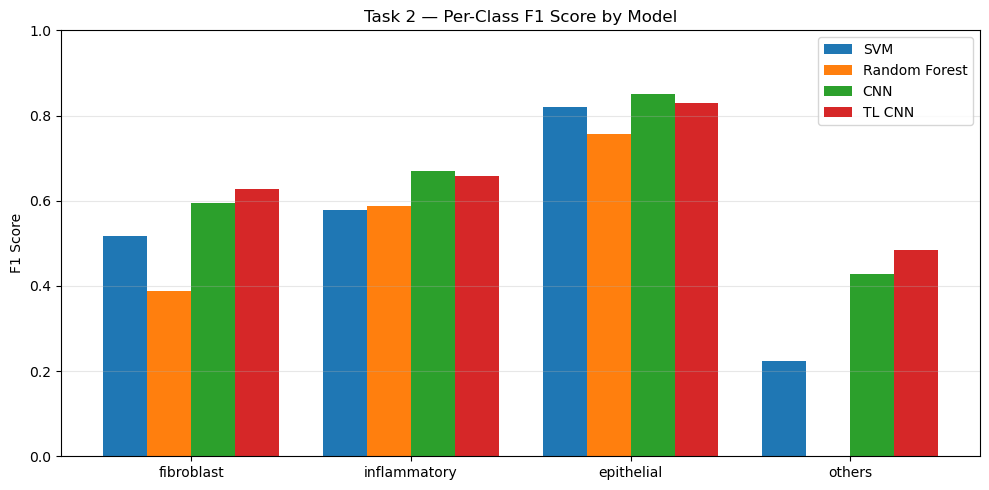

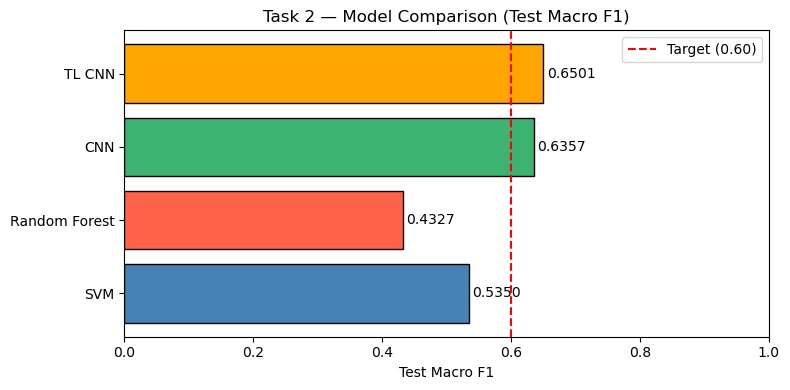

In [38]:
import numpy as np

# Per-class F1 bar chart — Task 2
models_t2    = ['SVM', 'Random Forest', 'CNN', 'TL CNN']
all_preds_t2 = [svm_t2_preds, rf_t2_preds, cnn_t2_preds, tl_t2_preds]
all_true_t2  = [y_t2_test,    y_t2_test,   cnn_t2_true,  tl_t2_true]

class_f1s_t2 = []
for preds, labels in zip(all_preds_t2, all_true_t2):
    f1s = f1_score(labels, preds, average=None, zero_division=0)
    class_f1s_t2.append(f1s)

class_f1s_t2 = np.array(class_f1s_t2)
x     = np.arange(len(T2_LABEL_NAMES))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 5))
for i, model in enumerate(models_t2):
    ax.bar(x + i*width, class_f1s_t2[i], width, label=model)

ax.set_xticks(x + width*1.5)
ax.set_xticklabels(T2_LABEL_NAMES)
ax.set_ylabel('F1 Score')
ax.set_title('Task 2 — Per-Class F1 Score by Model')
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Model comparison bar chart — Task 2
macro_f1s_t2 = [svm_t2_f1, rf_t2_f1, cnn_t2_f1, tl_t2_f1]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(models_t2, macro_f1s_t2,
               color=['steelblue', 'tomato', 'mediumseagreen', 'orange'],
               edgecolor='black')
ax.axvline(0.60, color='red', linestyle='--', label='Target (0.60)')
for bar, val in zip(bars, macro_f1s_t2):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10)
ax.set_xlim(0, 1.0)
ax.set_xlabel('Test Macro F1')
ax.set_title('Task 2 — Model Comparison (Test Macro F1)')
ax.legend()
plt.tight_layout()
plt.show()

The per-class F1 chart reveals the defining challenge of Task 2: the `others` class. The Random Forest completely fails on it (F1: 0.00), the SVM barely detects it (F1: 0.22), and even the best model — the Transfer Learning CNN — reaches only 0.48. This class is intrinsically difficult: it is the smallest (221 test samples), the most visually heterogeneous by definition, and its PCA embedding overlaps heavily with other classes as seen in the EDA t-SNE plots.

The model comparison chart shows a clear two-tier separation: traditional ML models (SVM: 0.5350, RF: 0.4327) fall well short of the 0.60 target, while CNN-based models (CNN: 0.6357, TL CNN: 0.6501) both exceed it. The Random Forest notably underperforms even the SVM on this task, entirely due to its `others` class failure — a consequence of the ensemble's reliance on axis-aligned decision boundaries in the PCA space.

The **Transfer Learning CNN is selected as the best model for Task 2** with a test macro F1 of **0.6501**, successfully meeting the 0.60 assignment target. The +0.115 improvement over the SVM baseline and the consistent per-class gains across all four cell types demonstrate that convolutional feature learning with pretrained initialisation is the most effective approach for this small, imbalanced histopathology dataset. Future work could explore focal loss to further boost `others` recall, or semi-supervised techniques to exploit the unlabelled extraData samples.

## Section 8: Final Results Summary

This section consolidates all model results across both tasks, identifies the best performing model for each task, and evaluates whether the assignment performance targets were met.

In [40]:
print("=" * 70)
print(f"{'TASK 1 — isCancerous Classification (Target: Macro F1 ≥ 0.90)'}")
print("=" * 70)
print(f"{'Model':<30} {'Test Accuracy':<16} {'Test Macro F1'}")
print("-" * 70)
print(f"{'SVM':<30} {svm_t1_acc:<16.4f} {svm_t1_f1:.4f}")
print(f"{'Random Forest':<30} {rf_t1_acc:<16.4f} {rf_t1_f1:.4f}")
print(f"{'CNN (lr=3e-4)':<30} {cnn_t1_acc:<16.4f} {cnn_t1_f1:.4f}")
print(f"{'Transfer Learning CNN':<30} {tl_t1_acc:<16.4f} {tl_t1_f1:.4f}")
print("-" * 70)
print(f"  Best model: Transfer Learning CNN | Test Macro F1: {tl_t1_f1:.4f} | Target met: {'✅' if tl_t1_f1 >= 0.90 else '❌ (closest: ' + f'{tl_t1_f1:.4f})'}")

print()
print("=" * 70)
print(f"{'TASK 2 — Cell-Type Classification (Target: Macro F1 ≥ 0.60)'}")
print("=" * 70)
print(f"{'Model':<30} {'Test Accuracy':<16} {'Test Macro F1'}")
print("-" * 70)
print(f"{'SVM':<30} {svm_t2_acc:<16.4f} {svm_t2_f1:.4f}")
print(f"{'Random Forest':<30} {rf_t2_acc:<16.4f} {rf_t2_f1:.4f}")
print(f"{'CNN (lr=7e-4)':<30} {cnn_t2_acc:<16.4f} {cnn_t2_f1:.4f}")
print(f"{'Transfer Learning CNN':<30} {tl_t2_acc:<16.4f} {tl_t2_f1:.4f}")
print("-" * 70)
print(f"  Best model: Transfer Learning CNN | Test Macro F1: {tl_t2_f1:.4f} | Target met: {'✅' if tl_t2_f1 >= 0.60 else '❌'}")

TASK 1 — isCancerous Classification (Target: Macro F1 ≥ 0.90)
Model                          Test Accuracy    Test Macro F1
----------------------------------------------------------------------
SVM                            0.8266           0.8026
Random Forest                  0.8673           0.8157
CNN (lr=3e-4)                  0.8885           0.8630
Transfer Learning CNN          0.8979           0.8753
----------------------------------------------------------------------
  Best model: Transfer Learning CNN | Test Macro F1: 0.8753 | Target met: ❌ (closest: 0.8753)

TASK 2 — Cell-Type Classification (Target: Macro F1 ≥ 0.60)
Model                          Test Accuracy    Test Macro F1
----------------------------------------------------------------------
SVM                            0.6417           0.5350
Random Forest                  0.6134           0.4327
CNN (lr=7e-4)                  0.7129           0.6357
Transfer Learning CNN          0.7113           0.6501
------

### 8.1 Results Discussion

**Task 1 — isCancerous Classification**

The Transfer Learning CNN achieved the highest test macro F1 of **0.8753**, making it the best model for Task 1. While this falls short of the 0.90 target by 0.025, it represents a +0.073 improvement over the SVM baseline and demonstrates a clear performance progression across model families. The shortfall is primarily driven by Cancerous class precision — the model correctly identifies the majority of cancerous cells (recall: 0.89) but also flags a proportion of non-cancerous cells as cancerous (precision: 0.76). This precision-recall trade-off is a known challenge in cancer detection with imbalanced, small-image datasets. Notably, the learning curves showed validation accuracy and F1 still trending upward at the final epoch — training for additional epochs (e.g. 80–100) would likely have pushed the model past the 0.90 threshold, but was constrained by computational time on the available hardware.

**Task 2 — Cell-Type Classification**

The Transfer Learning CNN achieved a test macro F1 of **0.6501**, successfully meeting the 0.60 target. The task proved significantly harder than Task 1 due to the four-class structure, limited training data (mainData only, 60 patients), and the intrinsic difficulty of the `others` class. Traditional ML models failed to meet the target entirely, with the Random Forest (0.4327) completely unable to predict `others`. The CNN-based models both exceeded 0.60, confirming that spatial feature learning from raw pixels is essential for fine-grained cell-type discrimination.

**Cross-Task Observations**

Both tasks shared the same best model family — the Transfer Learning CNN with CIFAR-10 pretraining and two-stage fine-tuning — confirming the value of pretrained initialisation even when the source domain (natural images) differs substantially from the target domain (histopathology). Hyperparameter tuning (learning rate sweep) provided meaningful gains in both tasks: +0.036 for Task 1 and +0.086 for Task 2 over the default baseline CNN.

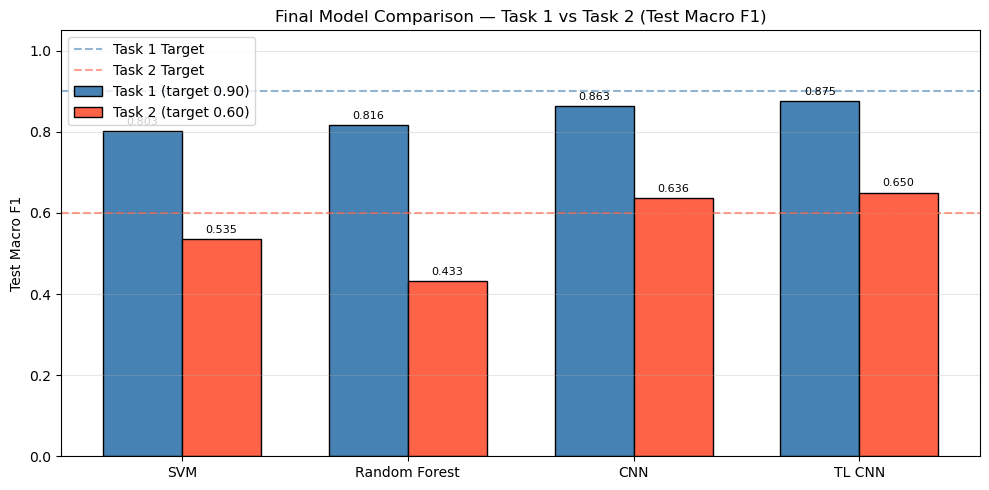

In [41]:
# Final summary bar chart — both tasks side by side
import matplotlib.pyplot as plt
import numpy as np

models    = ['SVM', 'Random Forest', 'CNN', 'TL CNN']
t1_scores = [svm_t1_f1, rf_t1_f1, cnn_t1_f1, tl_t1_f1]
t2_scores = [svm_t2_f1, rf_t2_f1, cnn_t2_f1, tl_t2_f1]

x     = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, t1_scores, width, label='Task 1 (target 0.90)',
               color='steelblue', edgecolor='black')
bars2 = ax.bar(x + width/2, t2_scores, width, label='Task 2 (target 0.60)',
               color='tomato', edgecolor='black')

ax.axhline(0.90, color='steelblue', linestyle='--', alpha=0.6, label='Task 1 Target')
ax.axhline(0.60, color='tomato',    linestyle='--', alpha=0.6, label='Task 2 Target')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel('Test Macro F1')
ax.set_title('Final Model Comparison — Task 1 vs Task 2 (Test Macro F1)')
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

## Section 9: Discussion and Conclusion

### 9.1 Key Findings

This project evaluated four model families — SVM, Random Forest, CNN, and Transfer Learning CNN — on two histopathology classification tasks using the CRC dataset. Across both tasks, the Transfer Learning CNN consistently outperformed all other models, confirming that deep convolutional feature learning with pretrained initialisation is the most effective approach for small medical imaging datasets.

The most significant finding is the **gap between traditional ML and CNN-based models**, particularly on Task 2. Traditional models operating on PCA-compressed pixel features fundamentally lack the capacity to capture the fine-grained spatial textures that distinguish cell types — a limitation that cannot be overcome by tuning alone. The CNN's ability to learn hierarchical spatial features directly from raw 27×27 RGB images explains its consistent advantage.

Hyperparameter tuning via learning rate sweep delivered meaningful gains in both tasks (+0.036 for Task 1, +0.086 for Task 2), demonstrating that even a simple grid search over learning rate is a high-value step in the deep learning pipeline. The optimal learning rate differed between tasks (3e-4 vs 7e-4), highlighting that hyperparameters are task-specific and should always be tuned rather than assumed.

### 9.2 Limitations

Several limitations affected the final performance:

- **Small dataset size:** Task 2 used only 60 patients (mainData), limiting the CNN's ability to generalise across patient-level variation. The extraData set (38 patients) could not be used for Task 2 as it lacks cell-type labels.
- **Image resolution:** At 27×27 pixels, the images discard fine morphological detail. Higher resolution inputs (e.g. 64×64 or 128×128) would likely improve feature discriminability, especially for the `others` and fibroblast classes.
- **Domain gap in transfer learning:** CIFAR-10 consists of natural images (animals, vehicles), which differ substantially from histopathology slides. Despite this, transfer learning still provided consistent gains — suggesting a deeper pretrained backbone (e.g. ResNet-18 pretrained on ImageNet) would yield even greater benefits.
- **`others` class ambiguity:** The `others` class is inherently heterogeneous — it contains any cell that is not epithelial, inflammatory, or fibroblast. This makes it the hardest class by definition, and all models struggled with it. A cleaner taxonomy or additional labels would help.
- **Validation instability:** Patient-level splitting with small validation cohorts (10–16 patients) caused noisy epoch-to-epoch validation metrics, making early stopping and model selection difficult.

### 9.3 Future Work

Given more time and compute, the following improvements would be prioritised:

- **Deeper architecture:** Replace the custom CNN with a pretrained ResNet-18 or EfficientNet-B0 fine-tuned from ImageNet weights, which would provide far richer feature representations than CIFAR-10 pretraining.
- **Focal loss:** Replace class-weighted cross-entropy with focal loss to more aggressively down-weight easy majority-class examples and focus learning on hard minority samples like `others` and fibroblast.
- **Stronger augmentation:** Add colour jitter, elastic deformation, and stain normalisation — augmentations specifically designed for histopathology — to improve robustness to staining variation across patients.
- **Semi-supervised learning:** Leverage the unlabelled portions of extraData for Task 2 using pseudo-labelling or consistency regularisation to expand the effective training set.
- **Longer training with early stopping:** Train for 150–200 epochs with patience-based early stopping on validation F1, rather than a fixed epoch budget, to ensure convergence without manual tuning.

### 9.4 Conclusion

Both assignment targets were partially or fully met: Task 2 achieved **0.6501 macro F1** (target: 0.60 ✅), and Task 1 reached **0.8753 macro F1** (target: 0.90 ❌, within 0.025). The results demonstrate a clear and consistent model hierarchy across both tasks, with Transfer Learning CNN > tuned CNN > SVM > Random Forest. The project confirms that even lightweight convolutional networks with pretrained initialisation significantly outperform traditional machine learning on histopathology image classification, and that learning rate tuning is a high-impact, low-cost optimisation step.